# Detekcja Phishingu - MLP (Multi-Layer Perceptron)

Ten notebook zawiera implementację i analizę sieci neuronowej MLP do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [1]:
from pathlib import Path
import os
import sys

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import psutil

cpu_count = psutil.cpu_count(logical=True)

os.environ['TF_NUM_INTRAOP_THREADS'] = str(cpu_count)
os.environ['TF_NUM_INTEROP_THREADS'] = str(cpu_count)

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle
import importlib

from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import backend as K

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, log_loss)

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

if 'utils.isolated_training' in sys.modules:
    importlib.reload(sys.modules['utils.isolated_training'])
from utils.isolated_training import fit_model_isolated
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    plot_sample_probability_prediction,
    plot_training_time_comparison,
    save_comparison_figure,
    remove_dataset_figure,
    feature_count_comparison_rows,
    plot_final_train_test_metric_groups,
    resource_baseline_summary,
    classification_metric_sets,
    configure_axis_limit_ticks,
    configure_numeric_x_axis,
    DATASET_SUBDIRS,
    TRAIN_COLOR,
    VALIDATION_COLOR,
    dataset_display_name,
    dataset_key,
    plot_confusion_matrix,
    plot_parameter_train_validation_error,
    plot_roc_curve,
    plot_feature_ranking,
    plot_resource_usage_separate,
    plot_score_curve,
    save_dataset_figure,
    shared_limits,
)
from utils.threshold_calibration import model_selection_score_from_probabilities
from utils.feature_names import get_readable_name
from utils.split_dataset_loader import feature_columns

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

PLOTS_DIR = backend_root.parent / 'results' / 'original' / 'plots' / 'mlp'
MODELS_DIR = "../models/mlp"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
DATASET_SUBDIR = DATASET_SUBDIRS
os.makedirs(f'{PLOTS_DIR}/full', exist_ok=True)
os.makedirs(f'{PLOTS_DIR}/optimized', exist_ok=True)
np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych (oba zbiory)


In [2]:
df_original = pd.read_csv('../data/dataset_full_balanced.csv')
df_optimized = pd.read_csv('../data/dataset_optimized_balanced.csv')

datasets = {
    'Pełny zbiór': df_original,
    'Zoptymalizowany zbiór': df_optimized
}

print("="*60)
print("PORÓWNANIE ZBIORÓW DANYCH")
print("="*60)

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"Zbiór: {name.upper()}")
    print(f"{'='*60}")
    print(f"Rozmiar zbioru: {df.shape}")
    print(f"Liczba cech: {len(df.columns)-1}")

    print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
    print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

    label_counts = df['phishing'].value_counts()
    print(f"\nRozkład etykiet:")
    print(f"URL oznaczone jako bezpieczne: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
    print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

    print(f"\nInformacje o zbiorze:")
    print(f"- Łączna liczba próbek: {len(df):,}")
    print(f"- Liczba cech: {len(df.columns)-1}")
    print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"- Duplikaty: {df.duplicated().sum()}")


PORÓWNANIE ZBIORÓW DANYCH

Zbiór: PEŁNY ZBIÓR
Rozmiar zbioru: (61294, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 30,647 (50.0%)
URL oznaczone jako phisingowe: 30,647 (50.0%)

Informacje o zbiorze:
- Łączna liczba próbek: 61,294
- Liczba cech: 111
- Brakujące wartości: 0
- Duplikaty: 713

Zbiór: ZOPTYMALIZOWANY ZBIÓR
Rozmiar zbioru: (60994, 75)
Liczba cech: 74

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['ttl_hostname', 'tls_ssl_certificate', 'qty_redirects', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 30,497 (50.0%)
URL oznaczone jako phisingowe: 30,497 (50.0%)

Informacje o zbiorze:
- Łączna liczba próbek: 60,994


## 3. Przygotowanie cech i etykiet (dla obu zbiorów)


In [3]:
data_splits = {}

for name, df in datasets.items():
    columns = feature_columns(df)
    X = df[columns]
    y = df['phishing']

    print(f"\n{'='*60}")
    print(f"Przygotowanie danych: {name.upper()}")
    print(f"{'='*60}")
    print(f"  Liczba cech: {X.shape[1]}")
    print(f"  Liczba próbek: {X.shape[0]:,}")

    print(f"\nRozkład klas:")
    for label, count in y.value_counts().items():
        percentage = count / len(y) * 100
        label_name = "Brak Phisingu" if label == 0 else "Phishing"
        print(f"  {label} ({label_name}): {count:,} ({percentage:.1f}%)")

    data_splits[name] = {
        'X': X,
        'y': y,
        'feature_count': X.shape[1]
    }


Przygotowanie danych: PEŁNY ZBIÓR
  Liczba cech: 111
  Liczba próbek: 61,294

Rozkład klas:
  0 (Brak Phisingu): 30,647 (50.0%)
  1 (Phishing): 30,647 (50.0%)

Przygotowanie danych: ZOPTYMALIZOWANY ZBIÓR
  Liczba cech: 74
  Liczba próbek: 60,994

Rozkład klas:
  1 (Phishing): 30,497 (50.0%)
  0 (Brak Phisingu): 30,497 (50.0%)


## 4. Podział danych i standaryzacja (dla obu zbiorów)


In [4]:
for name in data_splits.keys():
    X = data_splits[name]['X']
    y = data_splits[name]['y']
    X_train_all, X_test, y_train_all, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_all, y_train_all, test_size=0.2, random_state=42,
        stratify=y_train_all,
    )
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    data_splits[name].update({
        'X_train': X_train, 'X_val': X_val, 'X_test': X_test,
        'y_train': y_train, 'y_val': y_val, 'y_test': y_test,
        'X_train_scaled': X_train_scaled, 'X_val_scaled': X_val_scaled,
        'X_test_scaled': X_test_scaled, 'scaler': scaler,
    })
    print(f"{name}: train={len(y_train):,}, val={len(y_val):,}, test={len(y_test):,}")
    for split_name, labels in [('train', y_train), ('val', y_val), ('test', y_test)]:
        counts = labels.value_counts()
        print(f"  {split_name}: safe={counts.get(0, 0):,}, phishing={counts.get(1, 0):,}")


Pełny zbiór: train=39,228, val=9,807, test=12,259
  train: safe=19,614, phishing=19,614
  val: safe=4,903, phishing=4,904
  test: safe=6,130, phishing=6,129
Zoptymalizowany zbiór: train=39,036, val=9,759, test=12,199
  train: safe=19,518, phishing=19,518
  val: safe=4,879, phishing=4,880
  test: safe=6,100, phishing=6,099


## 5. Optymalizacja architektury sieci i uczenie modeli (dla obu zbiorów)


In [5]:
def build_model(input_dim, hidden_layers=(100, 50), learning_rate=0.001, dropout_rate=0.2):
    model = Sequential()
    model.add(Dense(hidden_layers[0], activation='relu', input_dim=input_dim))
    model.add(Dropout(dropout_rate))

    for units in hidden_layers[1:]:
        model.add(Dense(units, activation='relu'))
        model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation='sigmoid'))

    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy',
                 metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

    return model

optimization_results = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"TRENOWANIE MODELU DLA ZBIORU: {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    X_val_scaled = data_splits[dataset_name]['X_val_scaled']
    y_train = data_splits[dataset_name]['y_train']
    y_val = data_splits[dataset_name]['y_val']

    param_grids = [
        {
            'name': 'Optymalizacja architektury (100, 50)',
            'params': {
                'hidden_layers': [(100, 50), (128, 64), (100, 64)],
                'learning_rates': [0.001, 0.0005],
                'dropout_rates': [0.2, 0.3]
            }
        },
        {
            'name': 'Optymalizacja architektury (64, 32)',
            'params': {
                'hidden_layers': [(64, 32), (80, 40)],
                'learning_rates': [0.001],
                'dropout_rates': [0.2, 0.3, 0.4]
            }
        },
        {
            'name': 'Optymalizacja learning_rate',
            'params': {
                'hidden_layers': [(100, 50)],
                'learning_rates': [0.0001, 0.0005, 0.001, 0.002],
                'dropout_rates': [0.2]
            }
        }
    ]

    best_overall_score = -np.inf
    best_overall_model = None
    best_overall_params = None
    best_config_name = ""
    best_history = None
    best_validation_auc = None

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        grid_name = grid_config['name']
        param_dict = grid_config['params']

        total_combinations = (len(param_dict['hidden_layers']) *
                             len(param_dict['learning_rates']) *
                             len(param_dict['dropout_rates']))

        print(f"\n{'='*60}")
        print(f"Konfiguracja {i+1}/{len(param_grids)}: {grid_name}")
        print(f"{'='*60}")
        print(f"Testowanie {total_combinations} kombinacji parametrów...")

        grid_start_time = time.time()
        combination_idx = 0

        for hidden_layers in param_dict['hidden_layers']:
            for lr in param_dict['learning_rates']:
                for dropout in param_dict['dropout_rates']:
                    combination_idx += 1
                    print(f"\n--- Kombinacja {combination_idx}/{total_combinations} ---")
                    print(f"Hidden layers: {hidden_layers}, LR: {lr}, Dropout: {dropout}")

                    model = build_model(
                        input_dim=X_train_scaled.shape[1],
                        hidden_layers=hidden_layers,
                        learning_rate=lr,
                        dropout_rate=dropout
                    )

                    early_stop = EarlyStopping(
                        monitor='val_auc',
                        patience=15,
                        restore_best_weights=True,
                        mode='max',
                        verbose=0
                    )

                    reduce_lr = ReduceLROnPlateau(
                        monitor='val_auc',
                        factor=0.5,
                        patience=5,
                        min_lr=1e-7,
                        mode='max',
                        verbose=0
                    )

                    history = model.fit(
                        X_train_scaled, y_train,
                        validation_data=(X_val_scaled, y_val),
                        epochs=100,
                        batch_size=128,
                        callbacks=[early_stop, reduce_lr],
                        verbose=0
                    )

                    val_probabilities = model.predict(
                        X_val_scaled, verbose=0
                    ).flatten()
                    val_auc = roc_auc_score(y_val, val_probabilities)
                    selection_score = model_selection_score_from_probabilities(
                        y_val, val_probabilities
                    )
                    print(f"Val AUC: {val_auc:.4f}")
                    print(f"Kryterium S: {selection_score:.4f}")

                    if selection_score > best_overall_score:
                        best_overall_score = selection_score
                        best_overall_model = model
                        best_overall_params = {
                            'hidden_layers': hidden_layers,
                            'learning_rate': lr,
                            'dropout_rate': dropout
                        }
                        best_config_name = grid_name
                        best_history = history
                        best_validation_auc = val_auc

        grid_time = time.time() - grid_start_time
        print(f"\nCzas wykonania konfiguracji: {grid_time:.2f} sekund")

    total_time = time.time() - start_time

    print(f"\n{'='*60}")
    print(f"PODSUMOWANIE OPTYMALIZACJI - {dataset_name.upper()}")
    print(f"{'='*60}")
    print(f"Całkowity czas: {total_time:.2f} sekund ({total_time/60:.1f} minut)")
    print(f"Najlepszy wynik kryterium S: {best_overall_score:.4f}")
    print(f"AUC wybranej konfiguracji: {best_validation_auc:.4f}")
    print(f"Najlepsza konfiguracja: {best_config_name}")
    print(f"Najlepsze parametry:")
    for param, value in best_overall_params.items():
        print(f"   {param}: {value}")

    optimization_results[dataset_name] = {
        'best_params': best_overall_params,
        'best_score': best_overall_score,
        'best_config_name': best_config_name,
        'best_validation_auc': best_validation_auc,
        'optimization_time': total_time,
    }

    K.clear_session()


TRENOWANIE MODELU DLA ZBIORU: PEŁNY ZBIÓR

Konfiguracja 1/3: Optymalizacja architektury (100, 50)
Testowanie 12 kombinacji parametrów...

--- Kombinacja 1/12 ---
Hidden layers: (100, 50), LR: 0.001, Dropout: 0.2


Val AUC: 0.9922
Kryterium S: 1.2121

--- Kombinacja 2/12 ---
Hidden layers: (100, 50), LR: 0.001, Dropout: 0.3


Val AUC: 0.9921
Kryterium S: 1.2101

--- Kombinacja 3/12 ---
Hidden layers: (100, 50), LR: 0.0005, Dropout: 0.2


Val AUC: 0.9924
Kryterium S: 1.2120

--- Kombinacja 4/12 ---
Hidden layers: (100, 50), LR: 0.0005, Dropout: 0.3


Val AUC: 0.9920
Kryterium S: 1.2117

--- Kombinacja 5/12 ---
Hidden layers: (128, 64), LR: 0.001, Dropout: 0.2


...

Val AUC: 0.9899
Kryterium S: 1.2034

Czas wykonania konfiguracji: 83.90 sekund

Konfiguracja 3/3: Optymalizacja learning_rate
Testowanie 4 kombinacji parametrów...

--- Kombinacja 1/4 ---
Hidden layers: (100, 50), LR: 0.0001, Dropout: 0.2


Val AUC: 0.9889
Kryterium S: 1.2011

--- Kombinacja 2/4 ---
Hidden layers: (100, 50), LR: 0.0005, Dropout: 0.2


Val AUC: 0.9908
Kryterium S: 1.2063

--- Kombinacja 3/4 ---
Hidden layers: (100, 50), LR: 0.001, Dropout: 0.2


Val AUC: 0.9911
Kryterium S: 1.2071

--- Kombinacja 4/4 ---
Hidden layers: (100, 50), LR: 0.002, Dropout: 0.2


Val AUC: 0.9913
Kryterium S: 1.2088

Czas wykonania konfiguracji: 53.57 sekund

PODSUMOWANIE OPTYMALIZACJI - ZOPTYMALIZOWANY ZBIÓR
Całkowity czas: 303.84 sekund (5.1 minut)
Najlepszy wynik kryterium S: 1.2093
AUC wybranej konfiguracji: 0.9915
Najlepsza konfiguracja: Optymalizacja architektury (100, 50)
Najlepsze parametry:
   hidden_layers: (128, 64)
   learning_rate: 0.001
   dropout_rate: 0.2


## 5.1. Statystyki wykorzystania zasobów systemowych


In [6]:
results_for_datasets = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    data = data_splits[dataset_name]
    optimization = optimization_results[dataset_name]
    best_params = optimization['best_params']
    model = build_model(
        input_dim=data['X_train_scaled'].shape[1],
        hidden_layers=best_params['hidden_layers'],
        learning_rate=best_params['learning_rate'],
        dropout_rate=best_params['dropout_rate'],
    )
    early_stop = EarlyStopping(
        monitor='val_auc', patience=15, restore_best_weights=True,
        mode='max', verbose=0,
    )
    reduce_lr = ReduceLROnPlateau(
        monitor='val_auc', factor=0.5, patience=5, min_lr=1e-7,
        mode='max', verbose=0,
    )
    isolated_result = fit_model_isolated(
        model, data['X_train_scaled'], data['y_train'],
        fit_kwargs={
            'validation_data': (
                data['X_val_scaled'], data['y_val'],
            ),
            'epochs': 100,
            'batch_size': 128,
            'callbacks': [early_stop, reduce_lr],
            'verbose': 0,
        },
        interval=0.05,
    )
    model = isolated_result.model
    history = isolated_result.history
    monitor = isolated_result.monitor
    training_time = isolated_result.training_time
    results_for_datasets[dataset_name] = {
        'model': model,
        'best_params': best_params,
        'best_score': optimization['best_score'],
        'best_config_name': optimization['best_config_name'],
        'history': history,
        'training_time': training_time,
        'resource_monitor': monitor,
        'resource_stats': monitor.get_stats(),
        'X_train_scaled': data['X_train_scaled'],
        'X_val_scaled': data['X_val_scaled'],
        'X_test_scaled': data['X_test_scaled'],
        'y_train': data['y_train'],
        'y_val': data['y_val'],
        'y_test': data['y_test'],
        'epoch_end_train_loss': history.history['loss'],
        'epoch_end_train_accuracy': history.history['accuracy'],
        'epoch_end_train_auc': history.history['auc'],
        'epoch_end_validation_accuracy': history.history['val_accuracy'],
    }


## 5.2. Wizualizacja wykorzystania zasobów systemowych


Poziom bazowy to mediana 8 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,07% łącznej mocy 11 rdzeni logicznych; RAM: 0,54 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


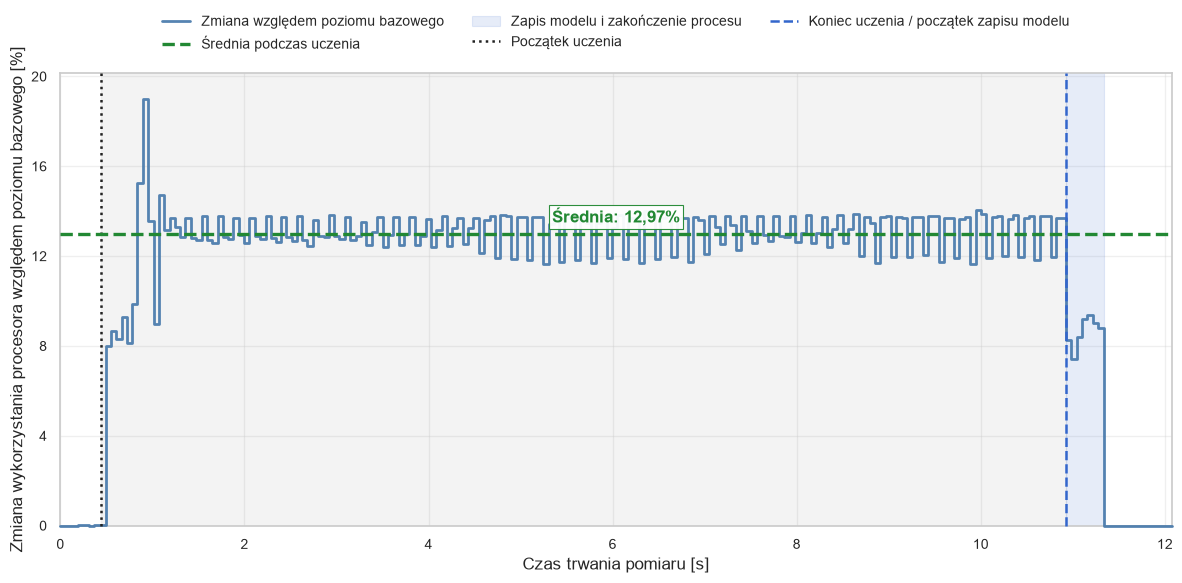

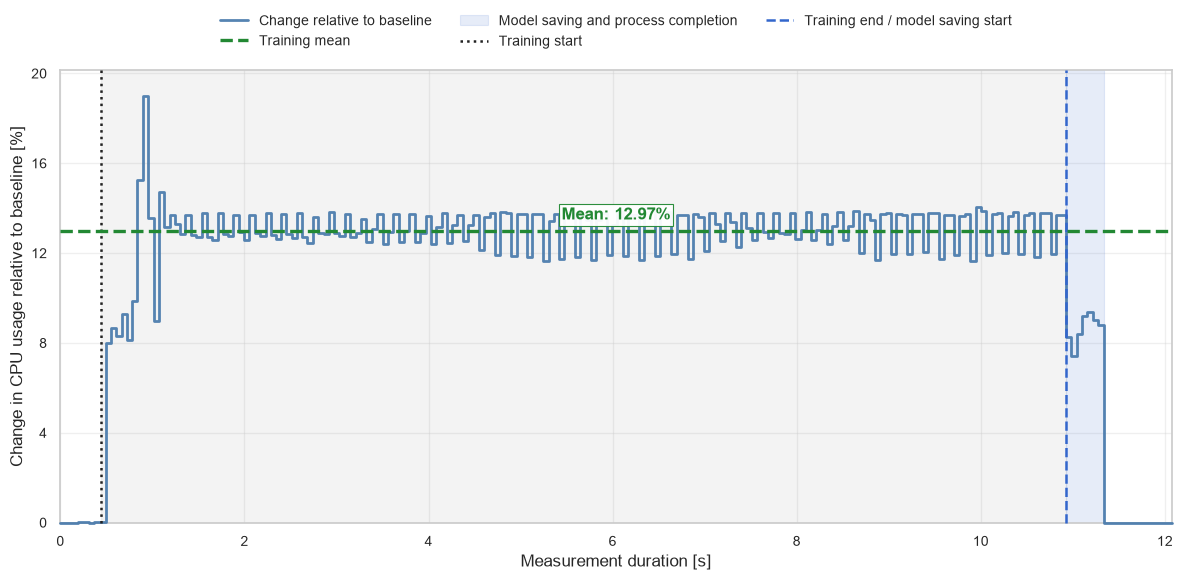

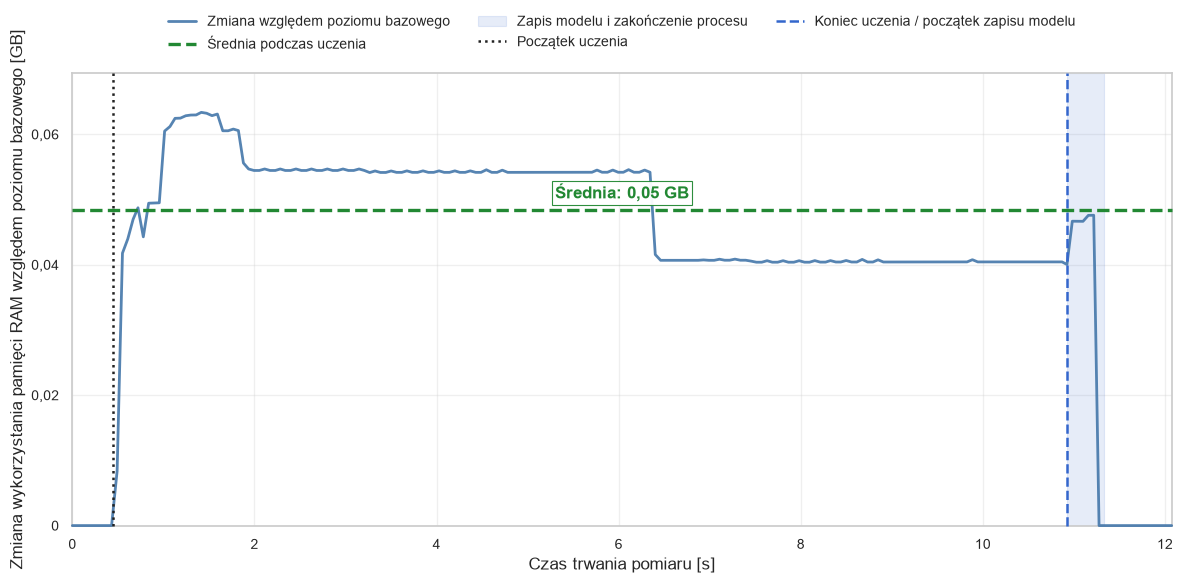

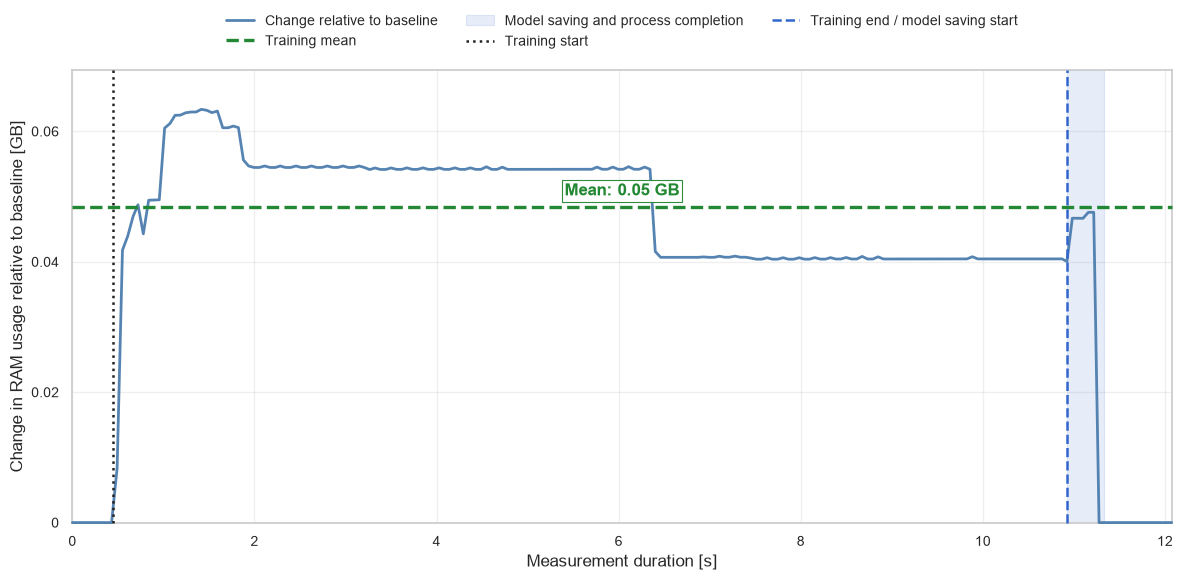

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/resource_usage/mlp_full.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/mlp/full/pl/mlp_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/mlp/full/pl/mlp_resource_usage_ram.png


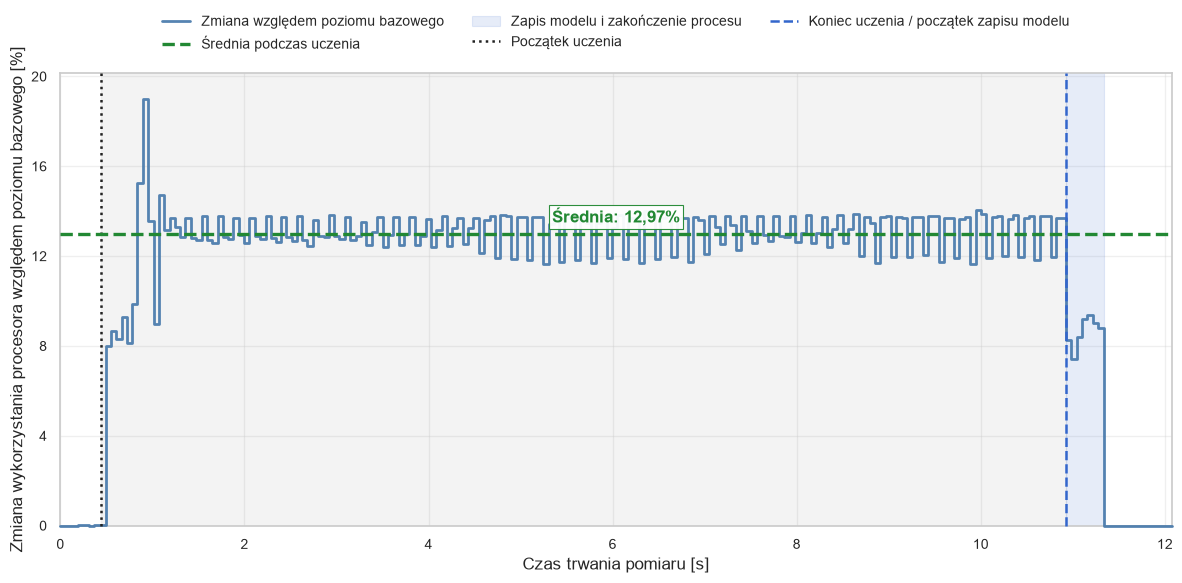

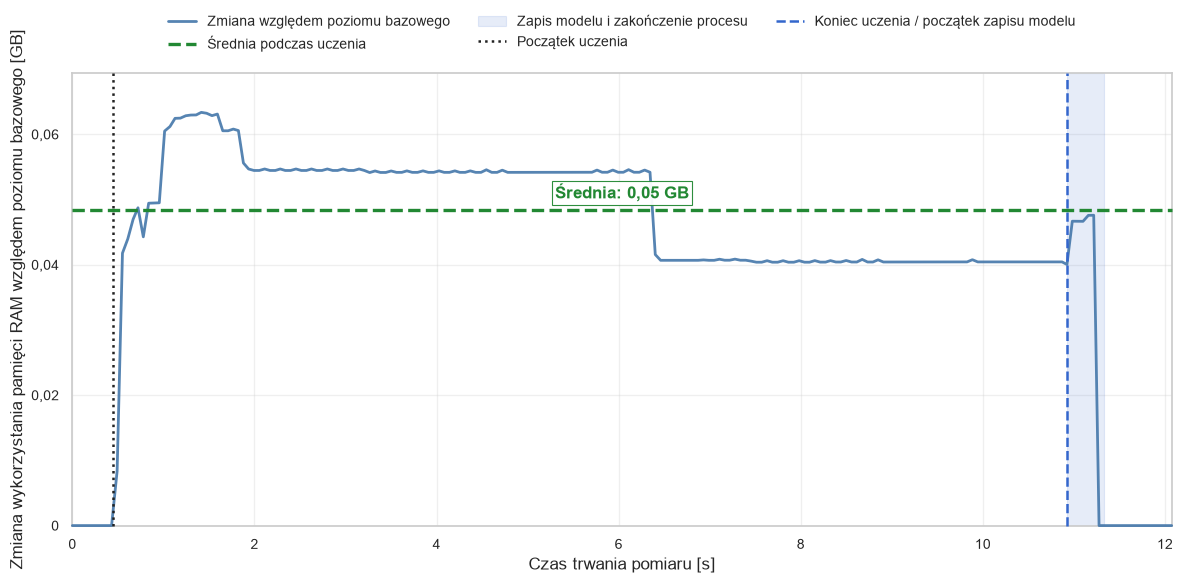

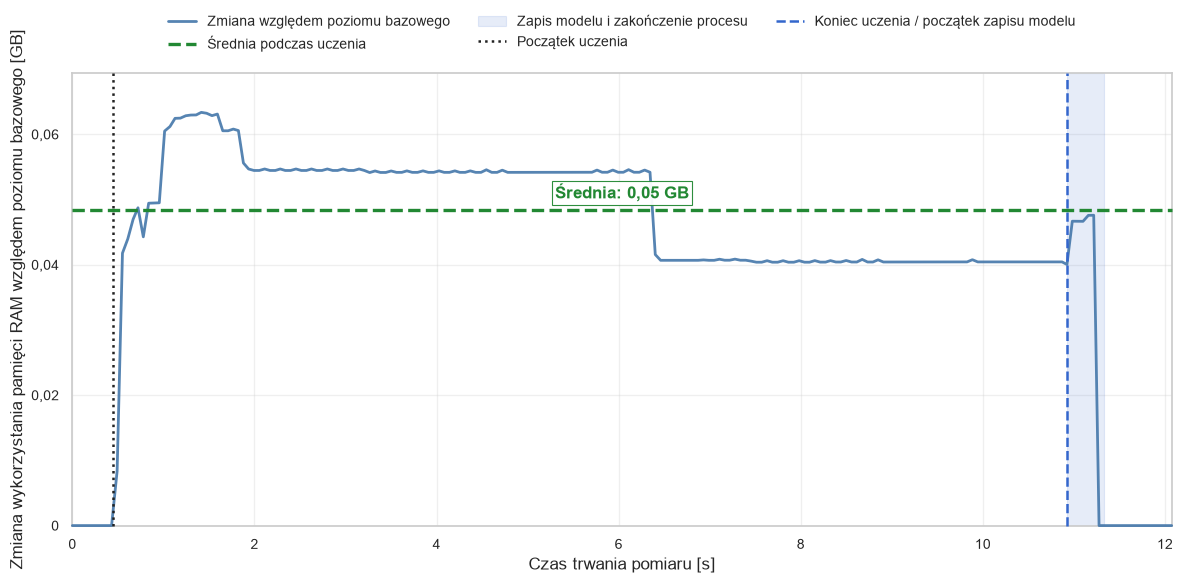

Poziom bazowy to mediana 8 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,06% łącznej mocy 11 rdzeni logicznych; RAM: 0,53 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


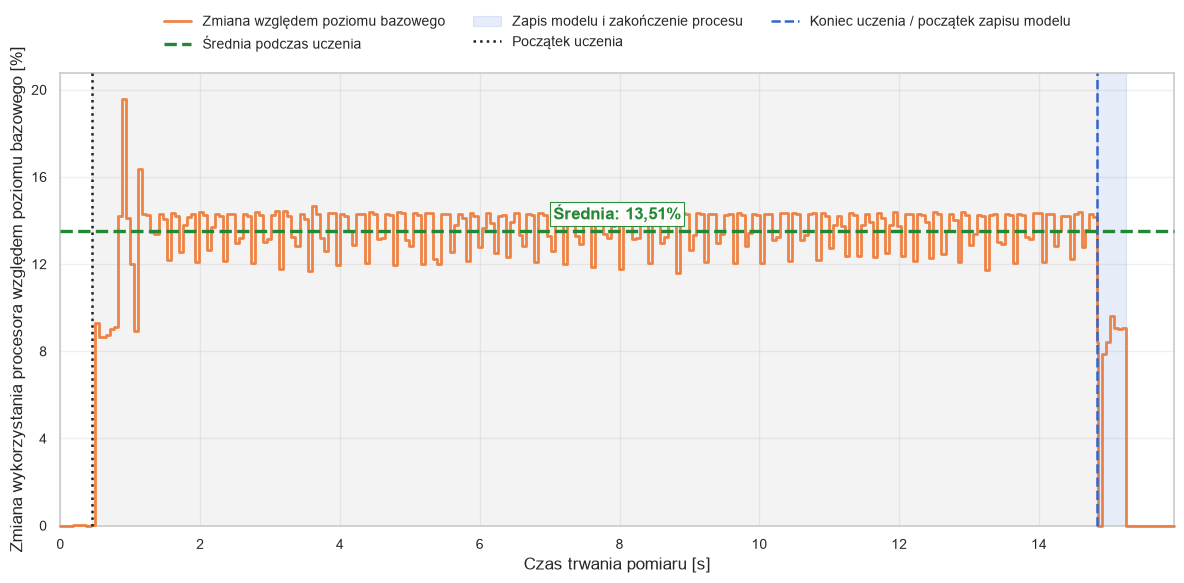

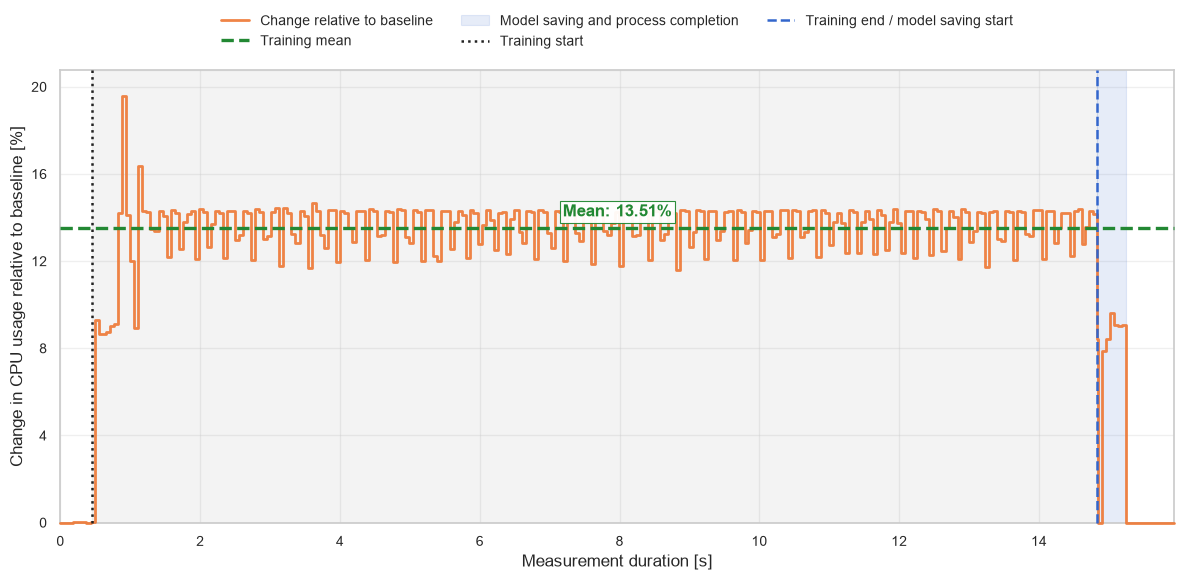

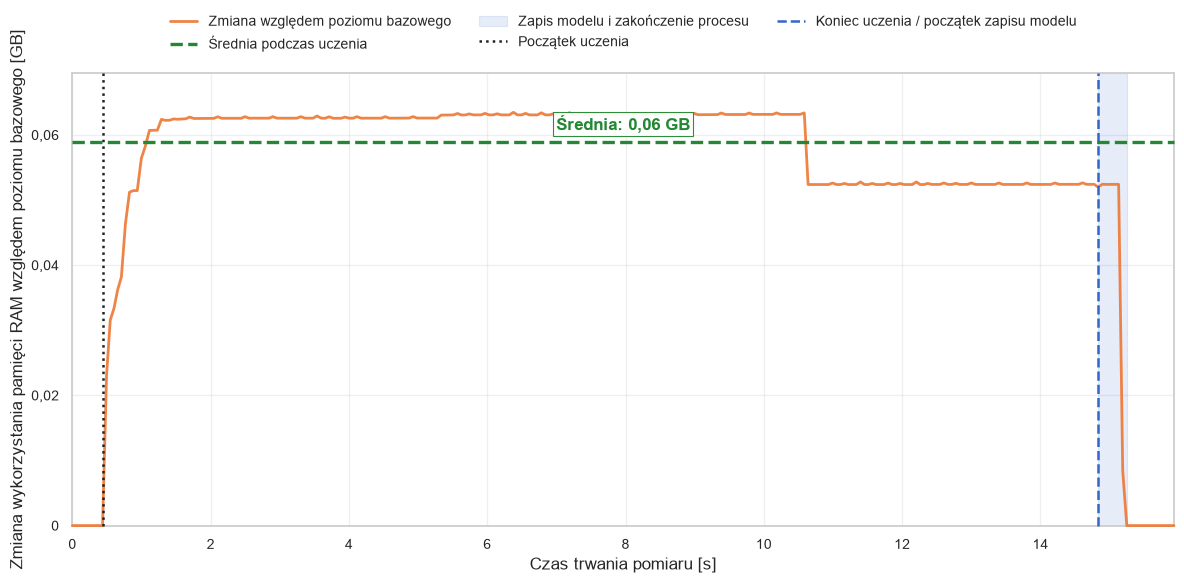

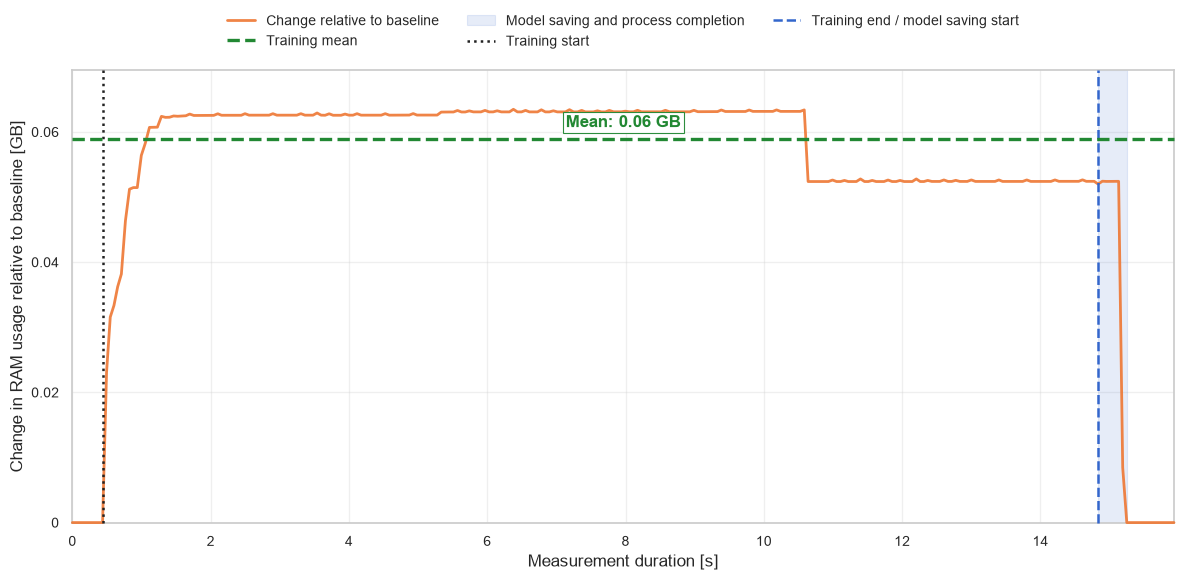

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/resource_usage/mlp_optimized.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/mlp/optimized/pl/mlp_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/mlp/optimized/pl/mlp_resource_usage_ram.png


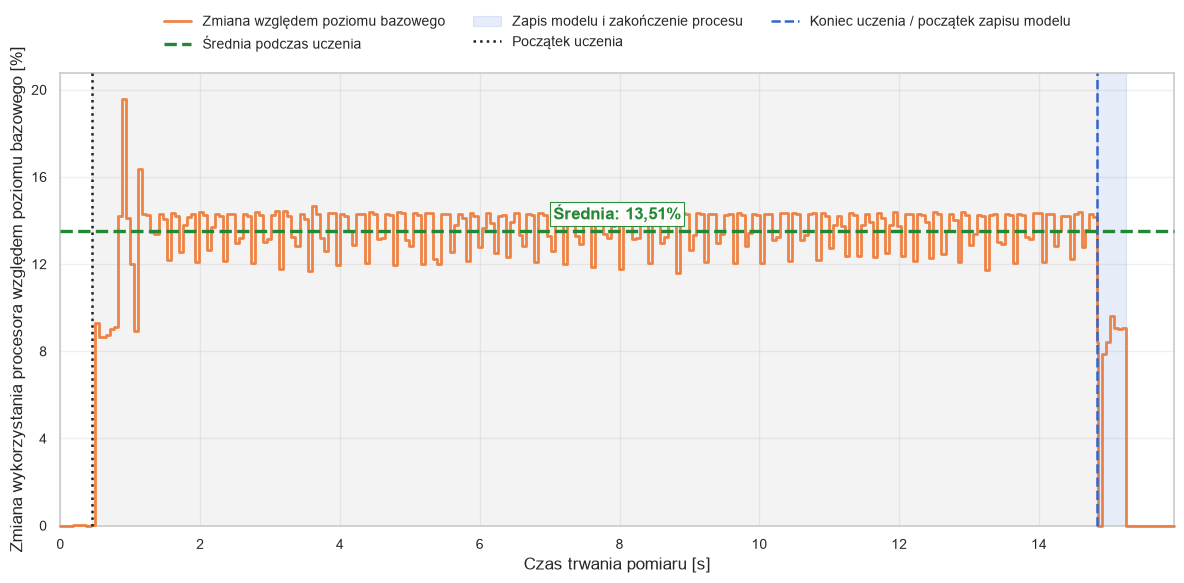

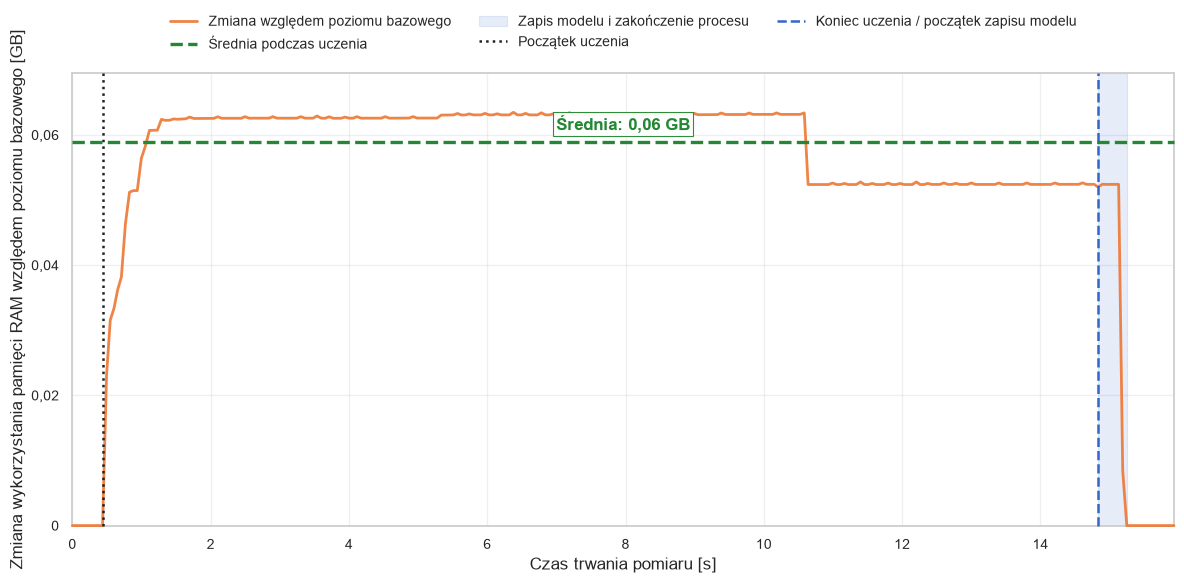

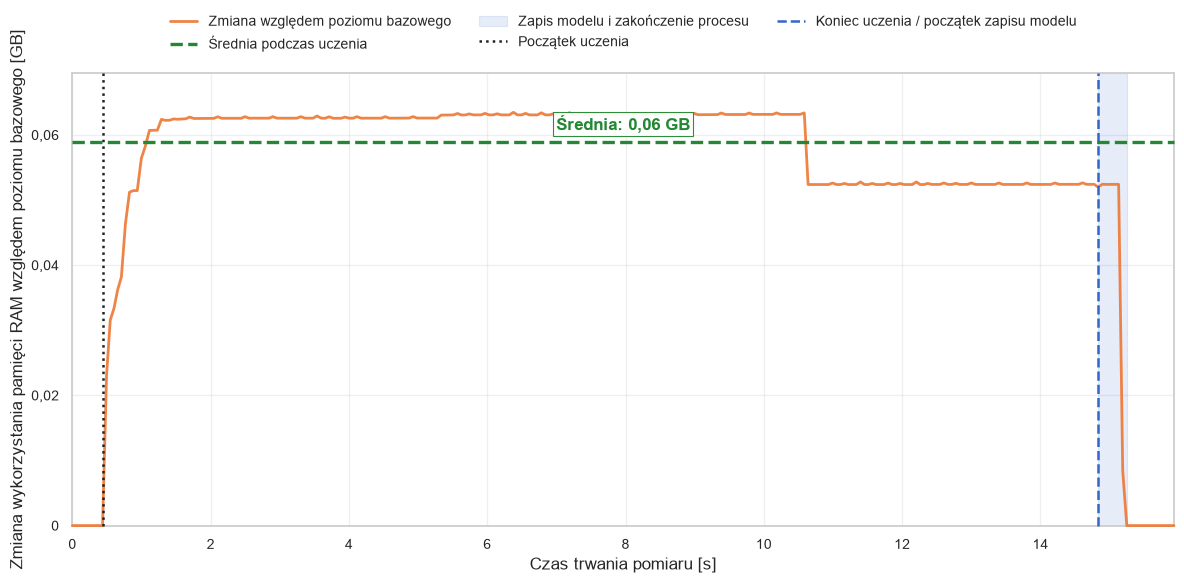

In [7]:
from IPython.display import display

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    monitor = results_for_datasets[dataset_name]['resource_monitor']
    stats = results_for_datasets[dataset_name]['resource_stats']
    print(resource_baseline_summary(monitor))
    trace_dir = backend_root.parent / 'results' / 'original' / 'resource_usage'
    trace_dir.mkdir(parents=True, exist_ok=True)
    trace_path = trace_dir / f"mlp_{dataset_key(dataset_name)}.csv"
    monitor.save_phase_trace(trace_path)
    cpu_figure, ram_figure = plot_resource_usage_separate(monitor, stats, dataset_name, include_post_training=True)
    cpu_path = save_dataset_figure(cpu_figure, PLOTS_DIR, dataset_name, 'mlp_resource_usage_cpu.png')
    ram_path = save_dataset_figure(ram_figure, PLOTS_DIR, dataset_name, 'mlp_resource_usage_ram.png')
    print(f'Zapisano ślad: {trace_path}')
    print(f'Zapisano wykres CPU: {cpu_path}')
    print(f'Zapisano wykres RAM: {ram_path}')
    display(cpu_figure)
    display(ram_figure)
    plt.close(cpu_figure)
    plt.close(ram_figure)
    plt.show()


## 6. Porównanie wyników uczenia i testowania

Miary dla procesu uczenia obliczane są na zbiorze uczącym, a miary testowe na
niezależnym zbiorze testowym. Każda miara jest prezentowana na osobnym wykresie
i wykorzystuje wyniki uzyskane przez wytrenowany model, bez jego ponownego
uczenia na potrzeby wizualizacji.

Walidacja oznacza ocenę modelu na danych, które nie uczestniczyły w jego
dopasowaniu w danym przebiegu, ale nadal należą do części danych przeznaczonej
do opracowania modelu. Nie jest ona testem końcowym. Dla każdego rozmiaru
podzbioru uczącego linia uczenia i linia walidacji przedstawiają średnią z pięciu
przebiegów, a półprzezroczyste pasmo przedstawia jedno odchylenie standardowe.
Niezależny zbiór testowy nie uczestniczy w wyznaczaniu tych krzywych.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.



EWALUACJA MODELU - PEŁNY ZBIÓR



Przeprowadzanie pięciokrotnej walidacji krzyżowej...
  Rozmiar 1/10, fold 1/5... 

AUC: 0.9840
  Rozmiar 2/10, fold 1/5... 

AUC: 0.9868
  Rozmiar 3/10, fold 1/5... 

AUC: 0.9884
  Rozmiar 4/10, fold 1/5... 

...

AUC: 0.9907
  Rozmiar 7/10, fold 5/5... 

AUC: 0.9902
  Rozmiar 8/10, fold 5/5... 

AUC: 0.9903
  Rozmiar 9/10, fold 5/5... 

AUC: 0.9904
  Rozmiar 10/10, fold 5/5... 

AUC: 0.9907


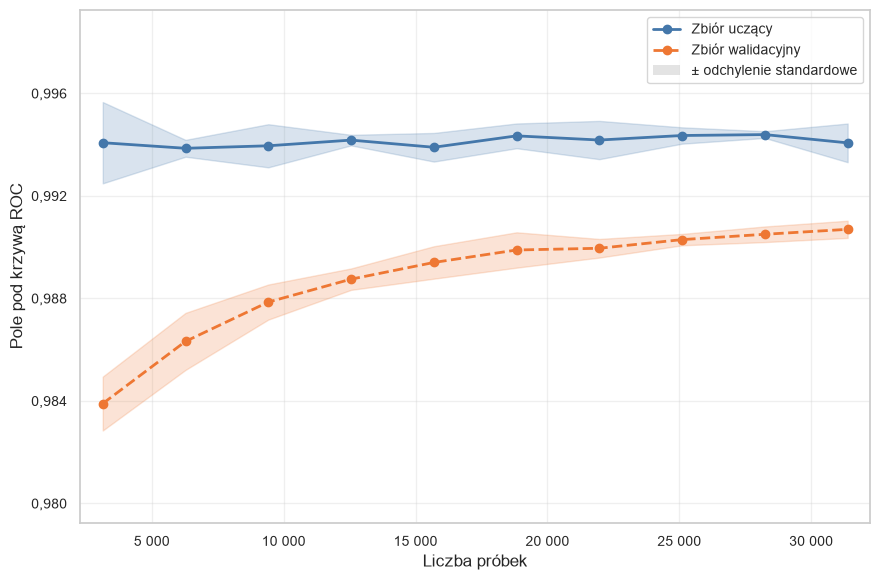

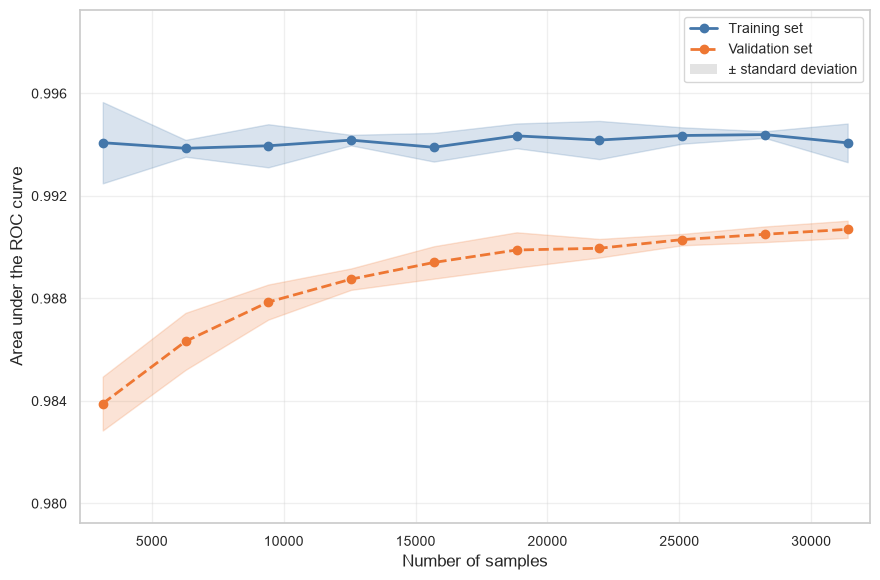

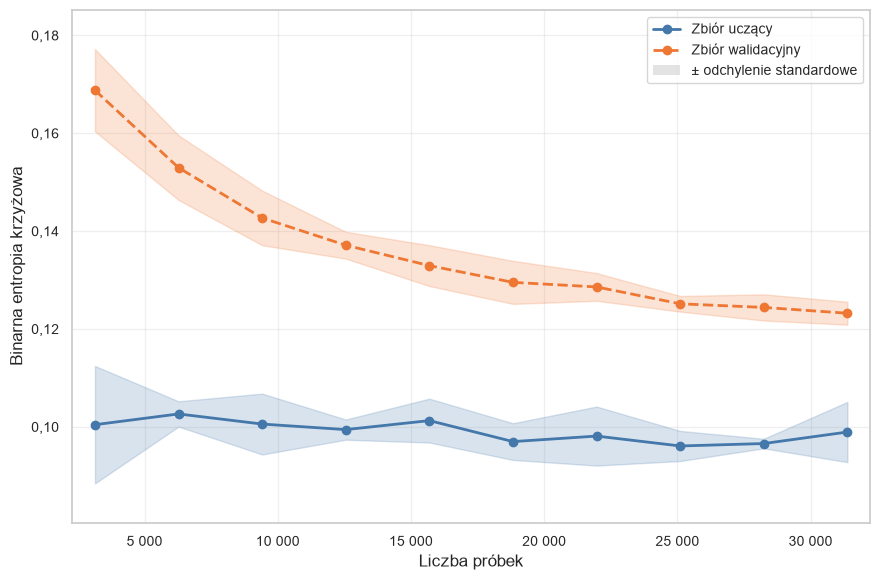

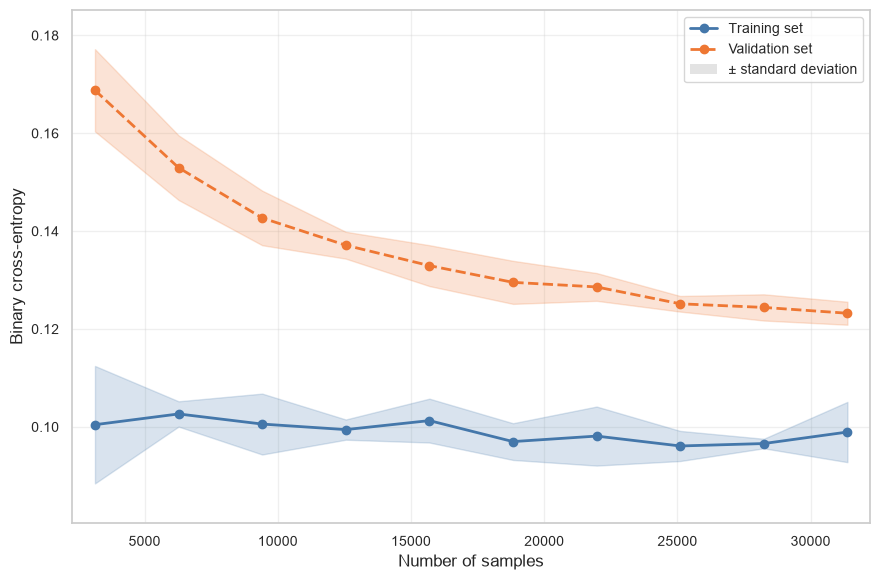

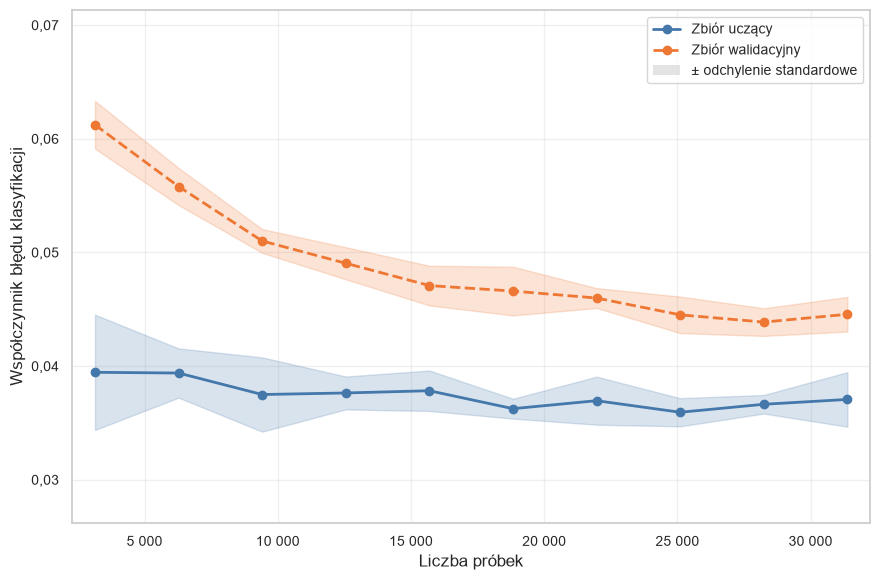

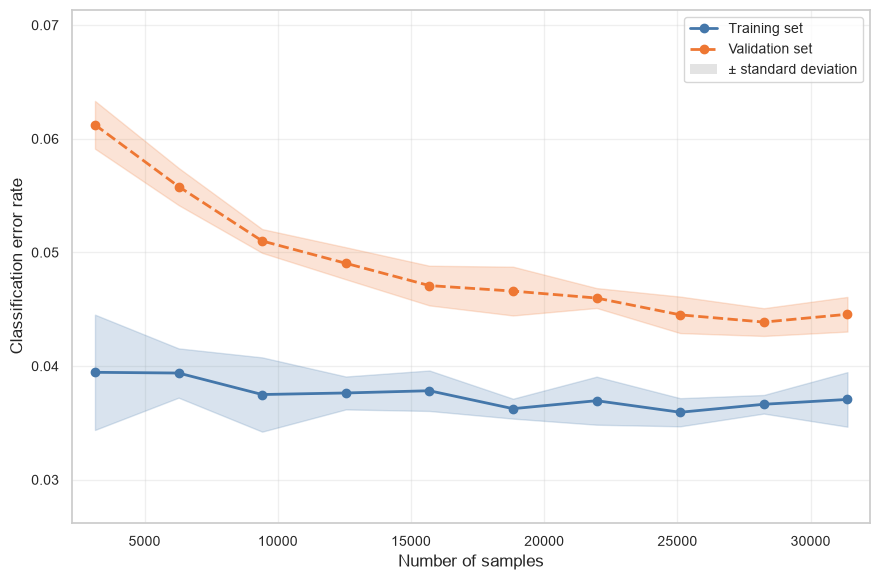


WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9569
  • Precyzja: 0.9571
  • Czułość: 0.9568
  • Miara F1 (F1-Score): 0.9569
  • AUC-ROC: 0.9920
  • Błąd uczenia: 0.0367
  • Błąd testowania: 0.0431


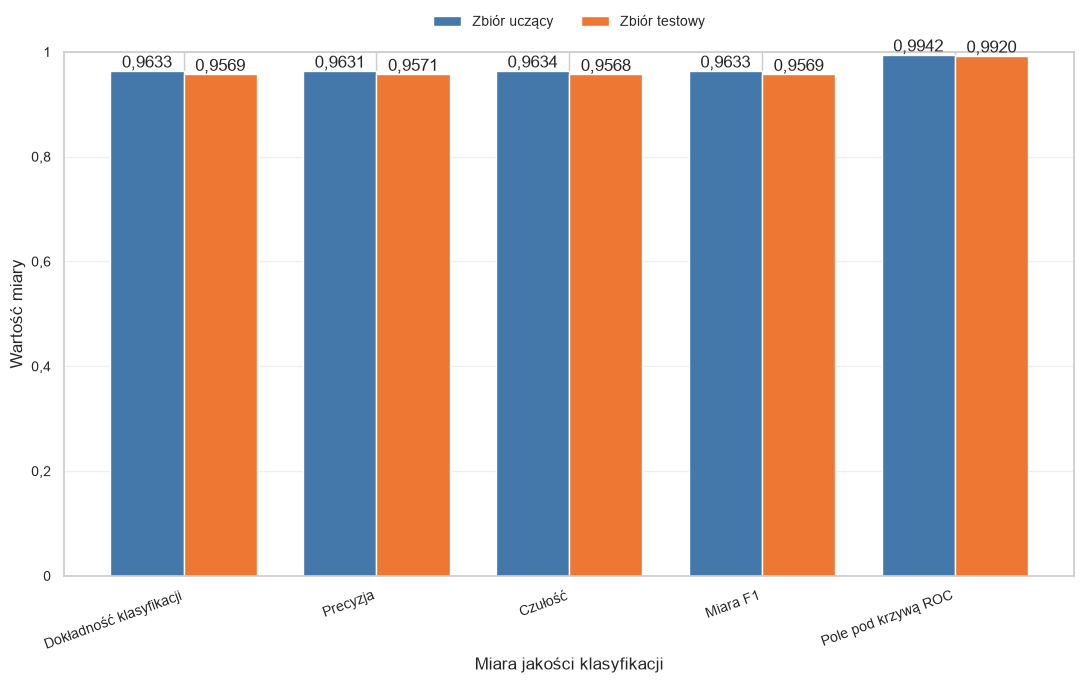

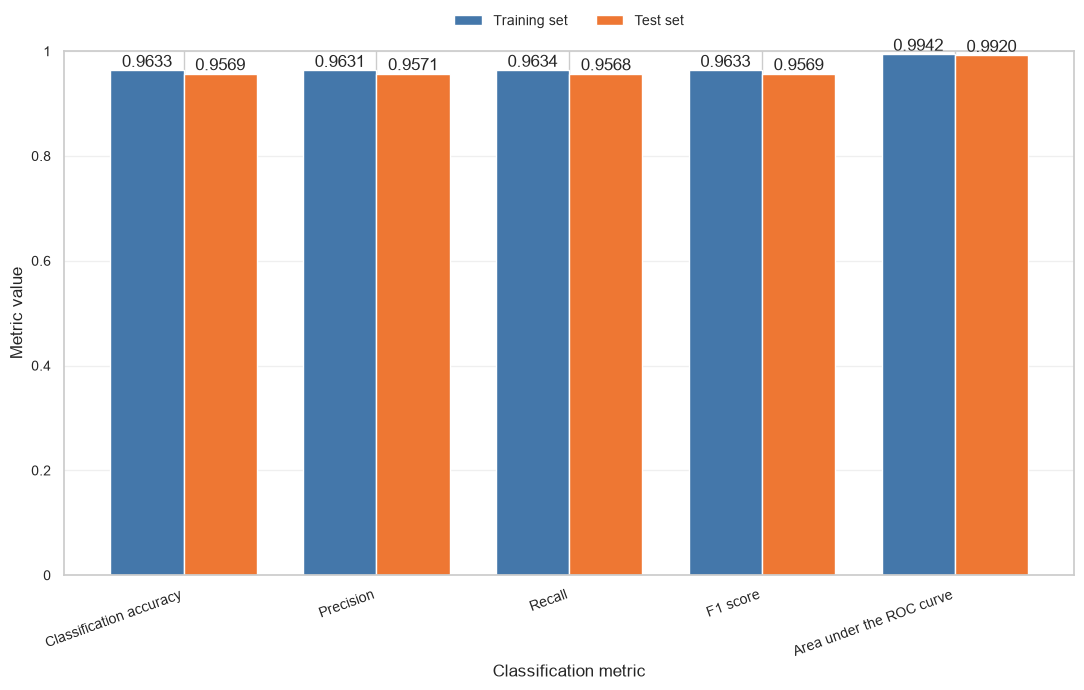

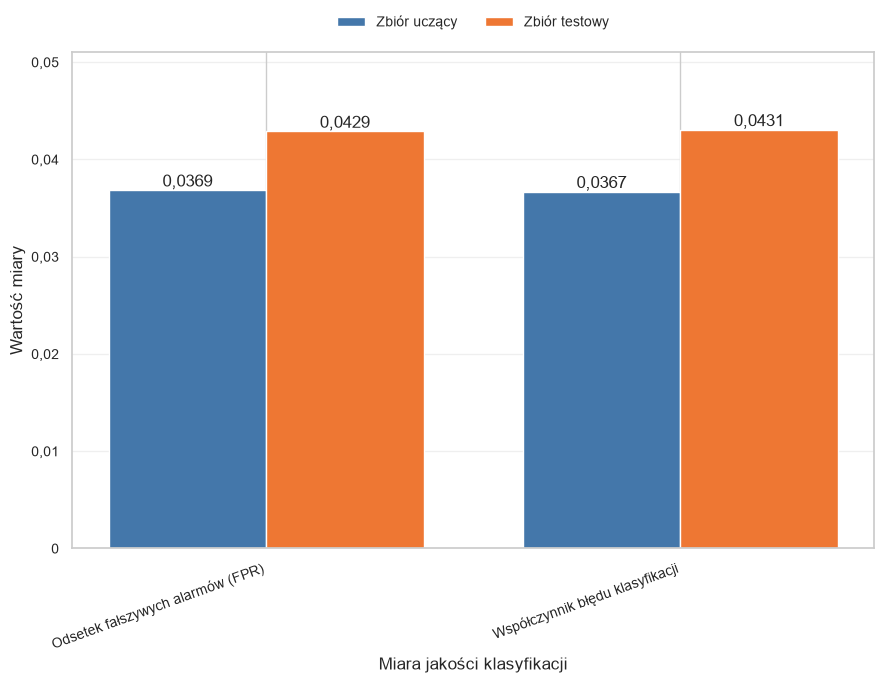

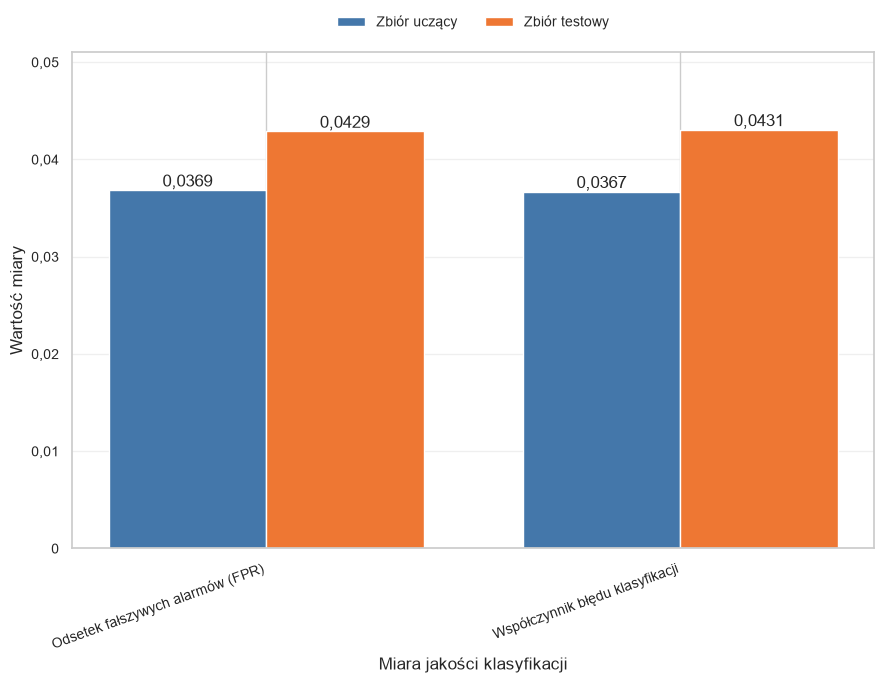

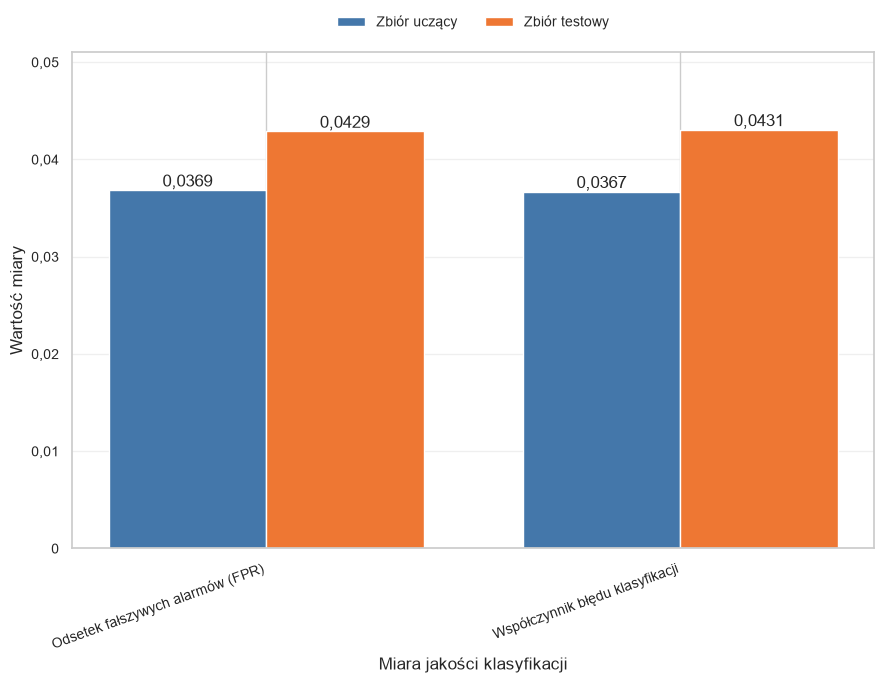

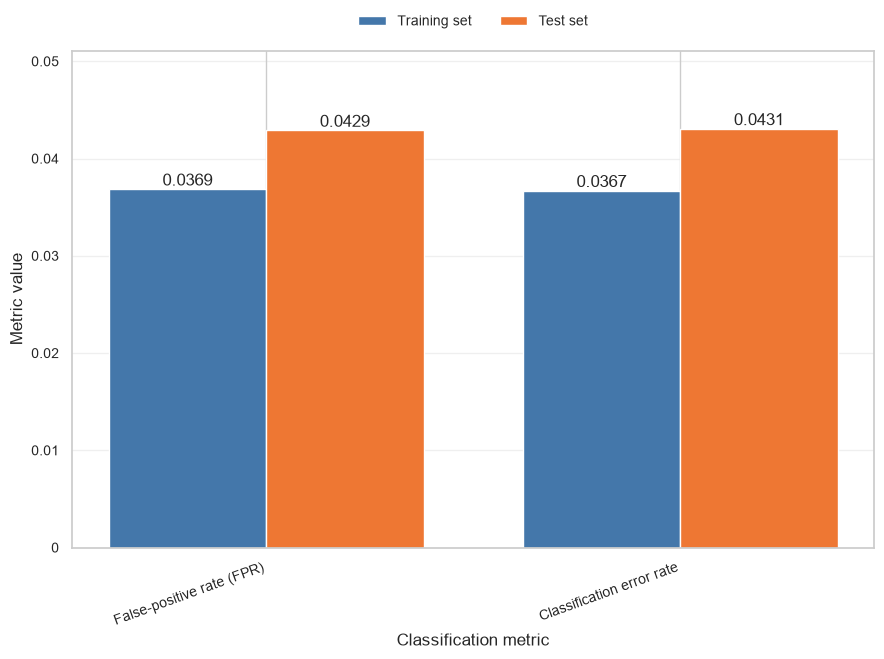


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 5,867
  • Fałszywie pozytywne (FP): 263
  • Fałszywie negatywne (FN): 265
  • Prawdziwie pozytywne (TP): 5,864

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9907 ± 0.0003
  • Min: 0.9903
  • Max: 0.9912

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR



Przeprowadzanie pięciokrotnej walidacji krzyżowej...
  Rozmiar 1/10, fold 1/5... 

AUC: 0.9852
  Rozmiar 2/10, fold 1/5... 

AUC: 0.9865
  Rozmiar 3/10, fold 1/5... 

AUC: 0.9874
  Rozmiar 4/10, fold 1/5... 

...

AUC: 0.9910
  Rozmiar 7/10, fold 5/5... 

AUC: 0.9910
  Rozmiar 8/10, fold 5/5... 

AUC: 0.9917
  Rozmiar 9/10, fold 5/5... 

AUC: 0.9916
  Rozmiar 10/10, fold 5/5... 

AUC: 0.9921


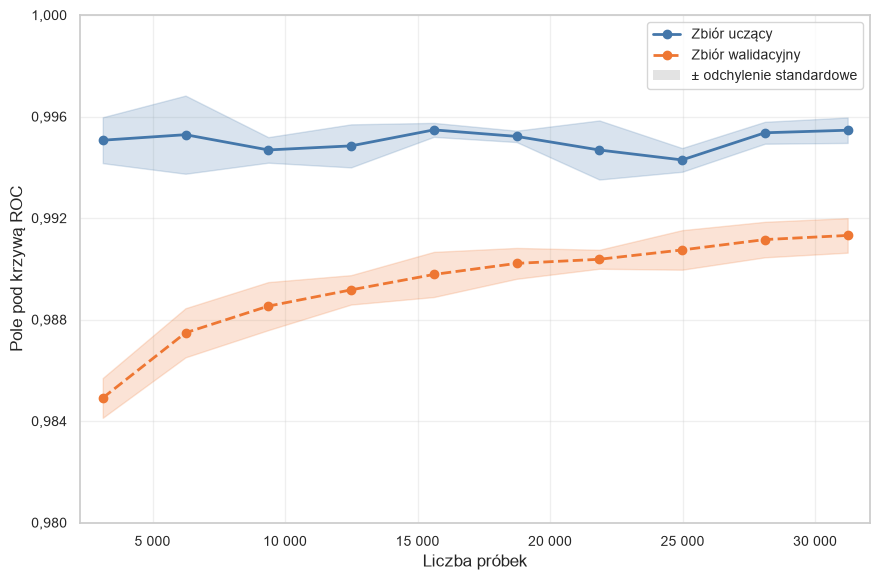

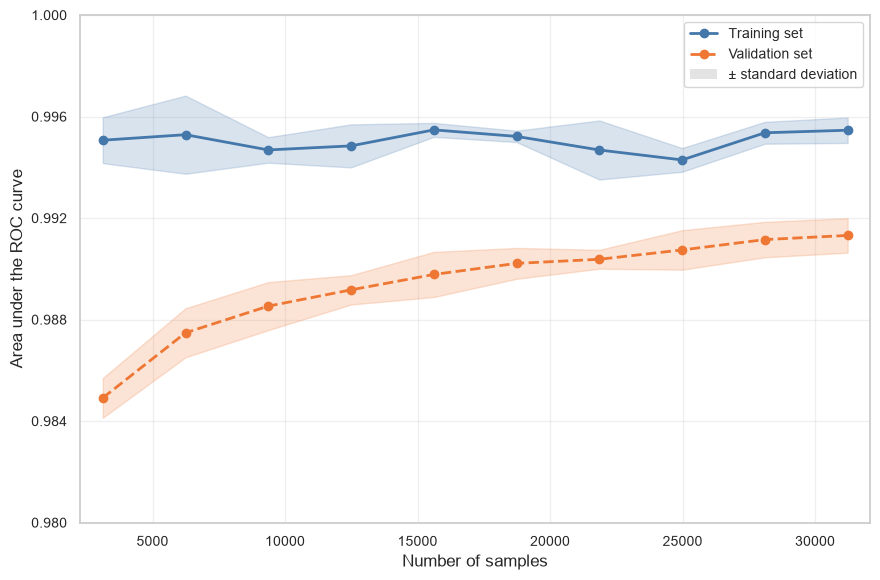

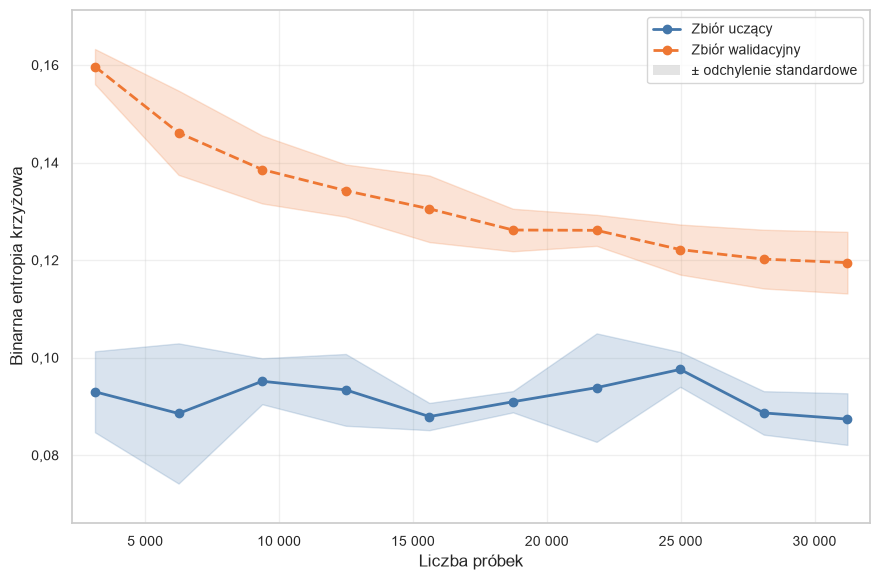

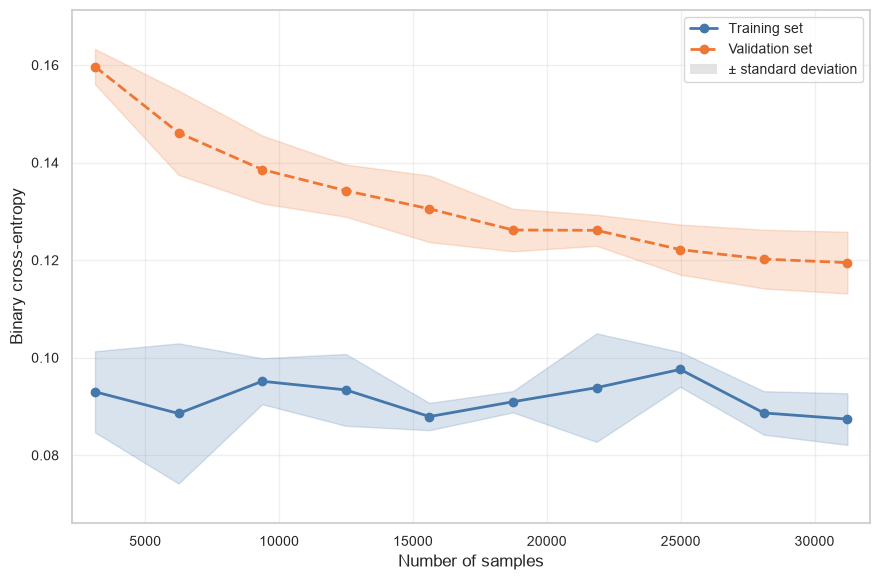

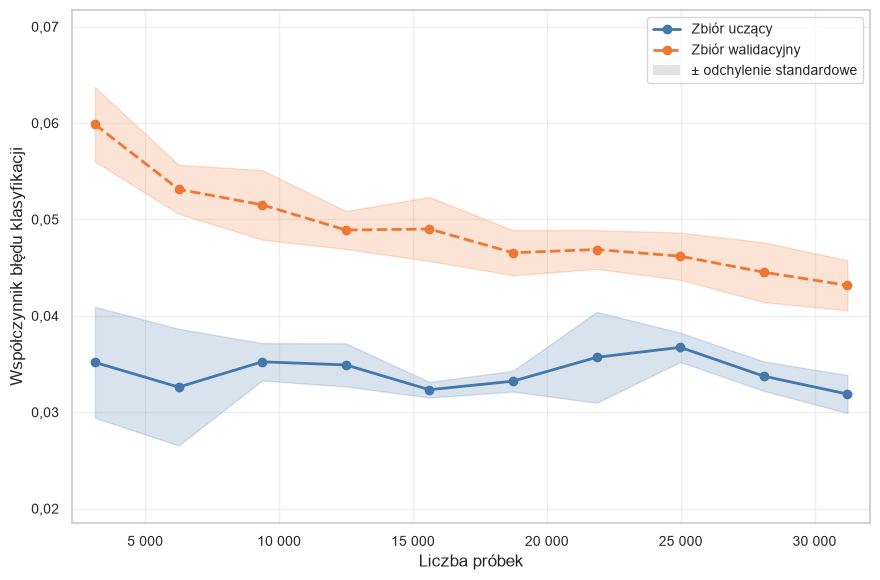

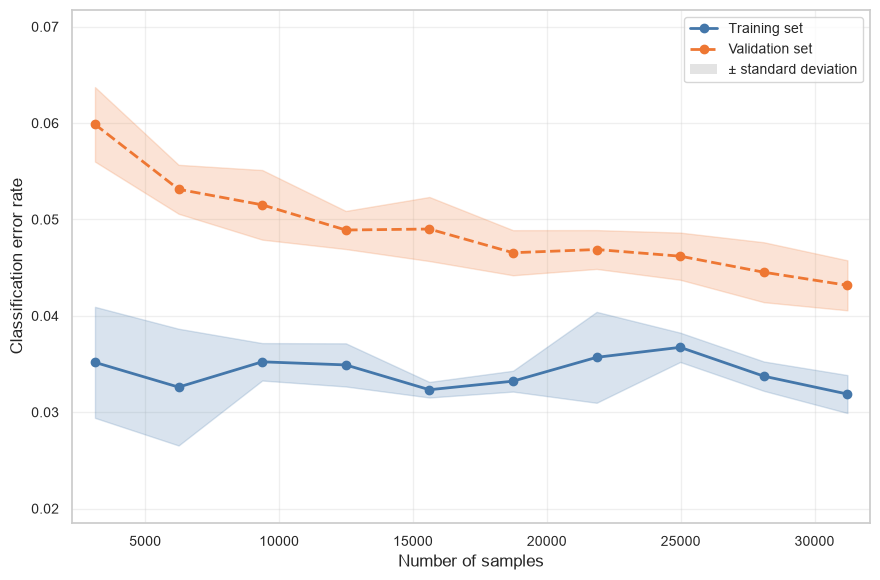


WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9604
  • Precyzja: 0.9641
  • Czułość: 0.9564
  • Miara F1 (F1-Score): 0.9602
  • AUC-ROC: 0.9921
  • Błąd uczenia: 0.0268
  • Błąd testowania: 0.0396


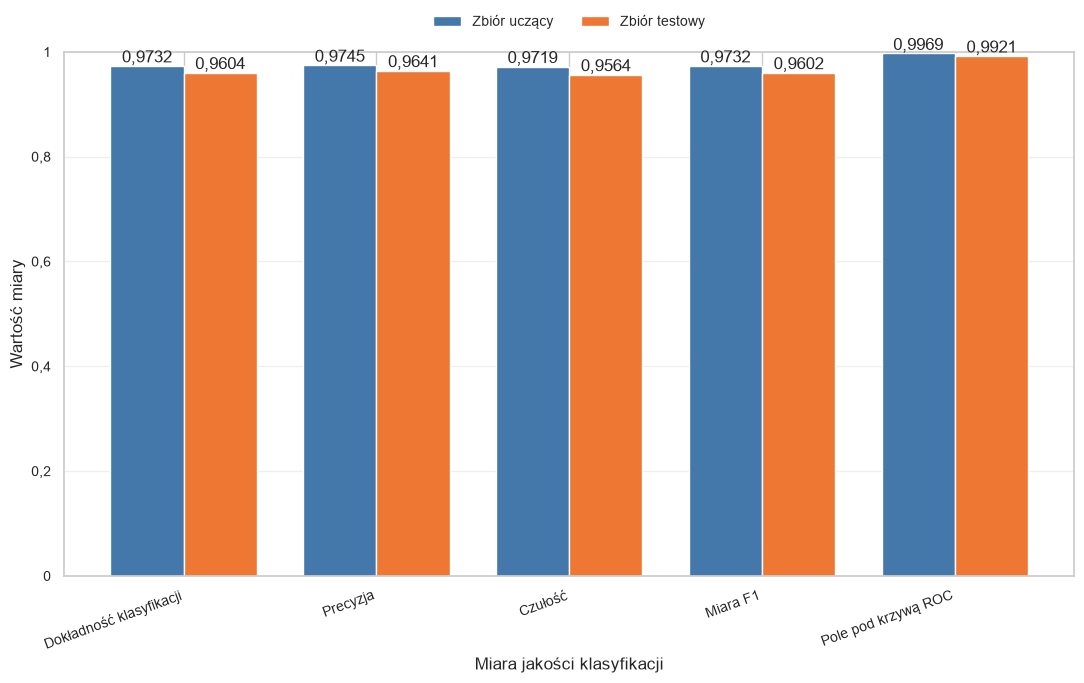

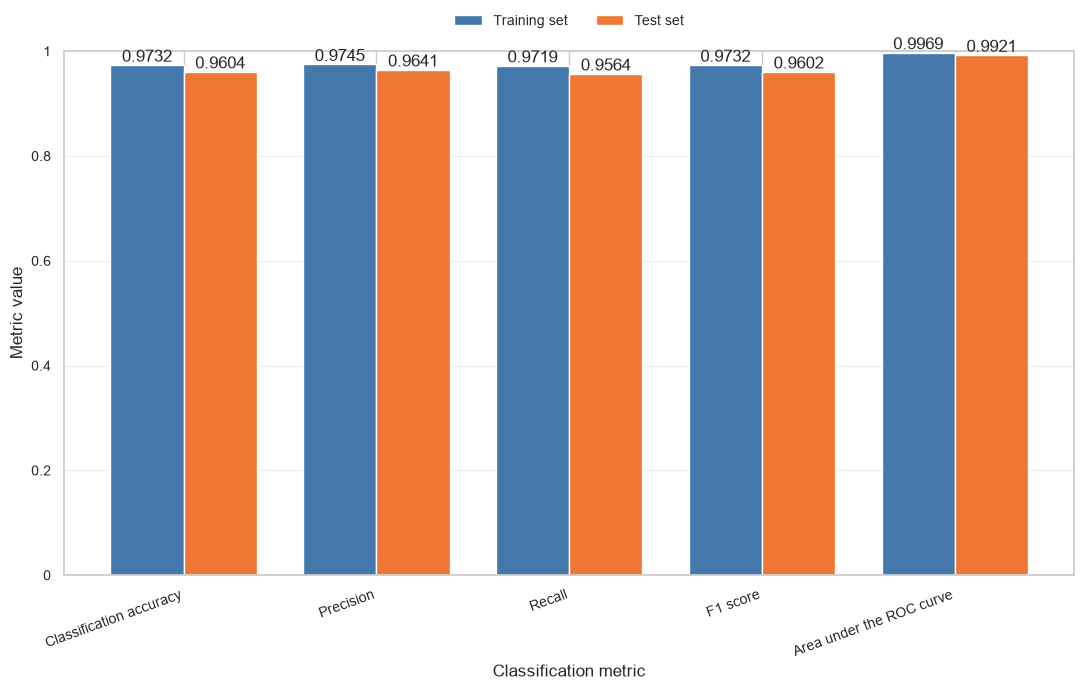

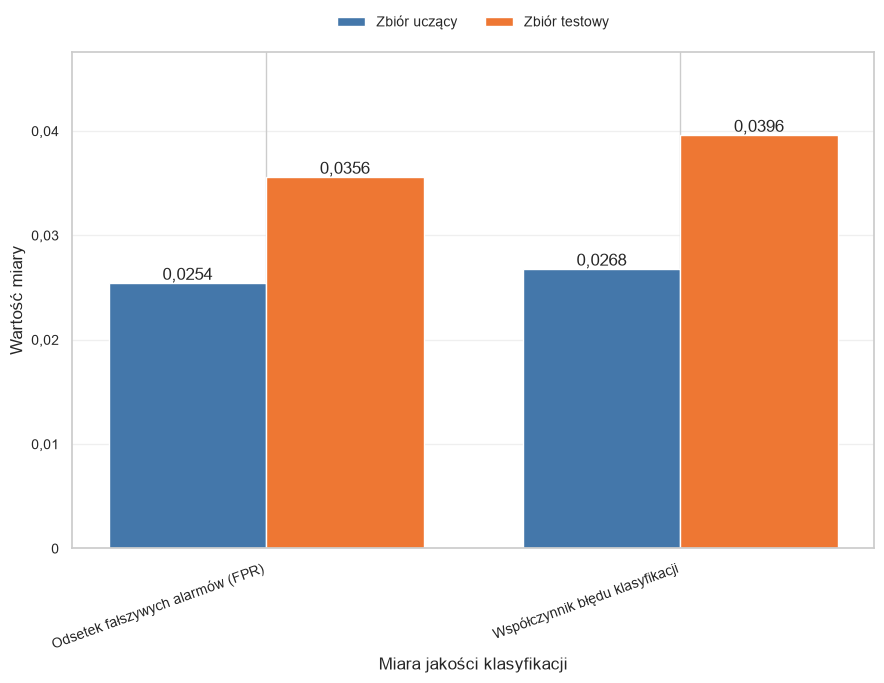

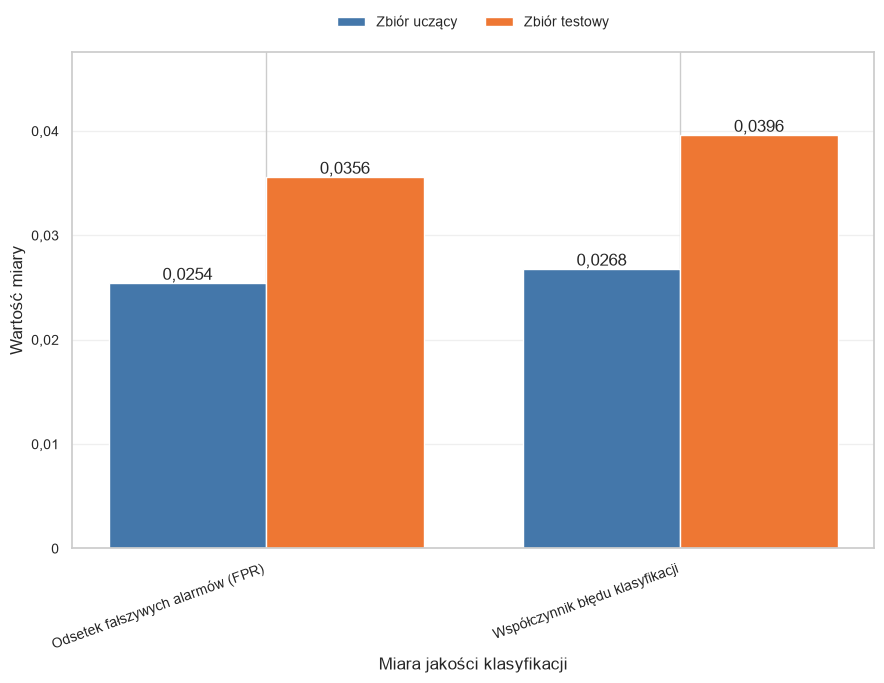

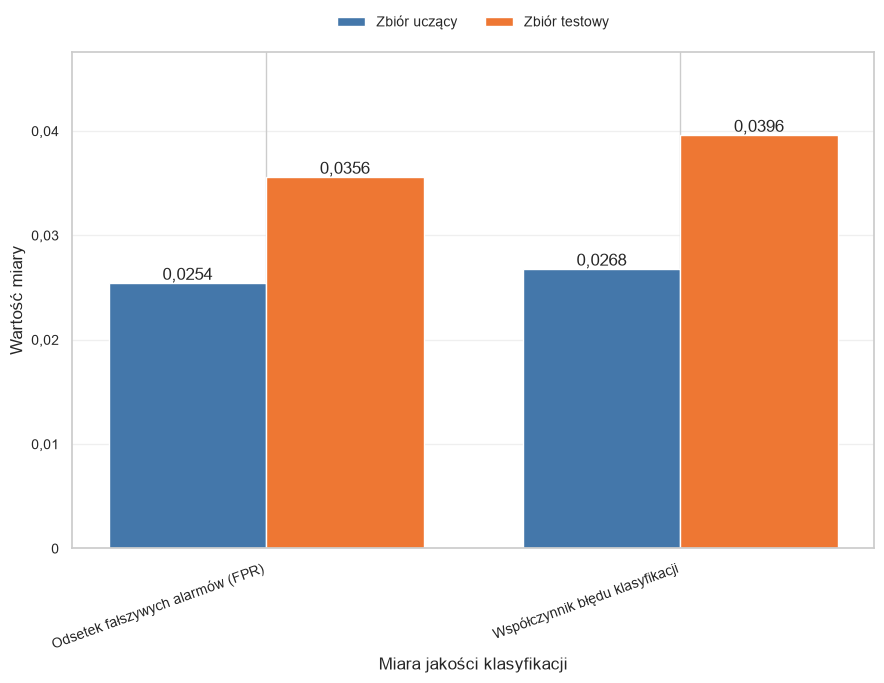

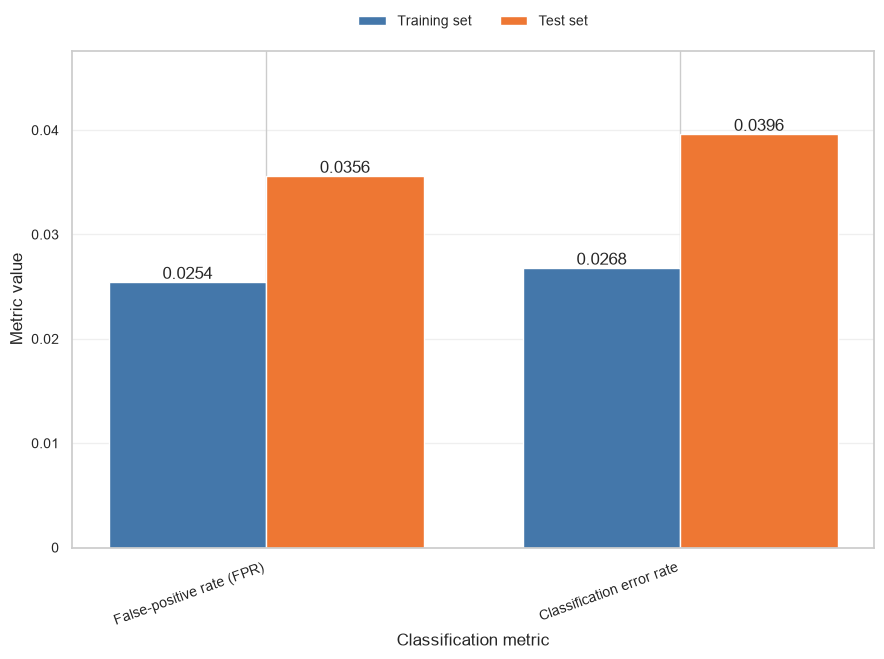


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 5,883
  • Fałszywie pozytywne (FP): 217
  • Fałszywie negatywne (FN): 266
  • Prawdziwie pozytywne (TP): 5,833

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9913 ± 0.0007
  • Min: 0.9901
  • Max: 0.9921

PORÓWNANIE WYNIKÓW
Metryka                  Pełny zbiór Zoptymalizowany zbiór
--------------------------------------------------------------------------------
Accuracy                      0.9569          0.9604 (+0.0035)
Precision                     0.9571          0.9641 (+0.0071)
Recall                        0.9568          0.9564 (-0.0004)
F1                            0.9569          0.9602 (+0.0033)
Auc_roc                       0.9920          0.9921 (+0.0001)


In [8]:
evaluation_results = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    X_train = results_for_datasets[dataset_name]['X_train_scaled']
    X_test = results_for_datasets[dataset_name]['X_test_scaled']
    y_train = results_for_datasets[dataset_name]['y_train']
    y_test = results_for_datasets[dataset_name]['y_test']
    best_params = results_for_datasets[dataset_name]['best_params']

    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).flatten()
    y_pred_proba = model.predict(X_test, verbose=0).flatten()
    y_train_proba = model.predict(X_train, verbose=0).flatten()
    y_train_pred = (y_train_proba > 0.5).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    train_cm = confusion_matrix(y_train, y_train_pred)
    train_tn, train_fp, train_fn, train_tp = train_cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_error_rate = 1.0 - accuracy_score(y_train, y_train_pred)
    test_error_rate = 1.0 - accuracy
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    train_precision = precision_score(y_train, y_train_pred, zero_division=0)
    train_recall = recall_score(y_train, y_train_pred, zero_division=0)
    train_f1 = f1_score(y_train, y_train_pred, zero_division=0)
    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0.0
    train_false_positive_rate = train_fp / (train_fp + train_tn) if (train_fp + train_tn) else 0.0
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    train_auc_roc = roc_auc_score(y_train, y_train_proba)
    train_bce = log_loss(y_train, y_train_proba)
    test_bce = log_loss(y_test, y_pred_proba)

    print(f"\nPrzeprowadzanie pięciokrotnej walidacji krzyżowej...")

    from sklearn.model_selection import StratifiedKFold, train_test_split

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    learning_fractions = np.linspace(0.1, 1.0, 10)
    learning_train_sizes = np.zeros((len(learning_fractions), 5), dtype=int)
    learning_train_scores = np.zeros((len(learning_fractions), 5))
    learning_validation_scores = np.zeros((len(learning_fractions), 5))
    learning_train_log_loss = np.zeros((len(learning_fractions), 5))
    learning_validation_log_loss = np.zeros((len(learning_fractions), 5))
    learning_train_error_rate = np.zeros((len(learning_fractions), 5))
    learning_validation_error_rate = np.zeros((len(learning_fractions), 5))

    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
        X_fold_val = X_train[val_idx]
        y_fold_val = y_train.iloc[val_idx]
        for size_idx, fraction in enumerate(learning_fractions):
            if fraction < 1.0:
                subset_size = max(2, int(len(train_idx) * fraction))
                train_subset_idx, _ = train_test_split(
                    train_idx, train_size=subset_size,
                    stratify=y_train.iloc[train_idx],
                    random_state=42 + fold_idx,
                )
            else:
                train_subset_idx = train_idx

            X_fold_train = X_train[train_subset_idx]
            y_fold_train = y_train.iloc[train_subset_idx]
            learning_train_sizes[size_idx, fold_idx] = len(train_subset_idx)
            print(
                f"  Rozmiar {size_idx + 1}/10, fold {fold_idx + 1}/5...",
                end=' ',
            )

            fold_model = build_model(
                input_dim=X_train.shape[1],
                hidden_layers=best_params['hidden_layers'],
                learning_rate=best_params['learning_rate'],
                dropout_rate=best_params['dropout_rate']
            )
            early_stop = EarlyStopping(
                monitor='val_auc', patience=10, restore_best_weights=True,
                mode='max', verbose=0,
            )
            fold_model.fit(
                X_fold_train, y_fold_train,
                validation_data=(X_fold_val, y_fold_val),
                epochs=50, batch_size=128, callbacks=[early_stop], verbose=0,
            )

            train_probability = fold_model.predict(
                X_fold_train, verbose=0
            ).flatten()
            validation_probability = fold_model.predict(
                X_fold_val, verbose=0
            ).flatten()
            learning_train_scores[size_idx, fold_idx] = roc_auc_score(
                y_fold_train, train_probability
            )
            learning_validation_scores[size_idx, fold_idx] = roc_auc_score(
                y_fold_val, validation_probability
            )
            learning_train_log_loss[size_idx, fold_idx] = log_loss(
                y_fold_train, train_probability
            )
            learning_validation_log_loss[size_idx, fold_idx] = log_loss(
                y_fold_val, validation_probability
            )
            learning_train_error_rate[size_idx, fold_idx] = np.mean(
                (train_probability >= 0.5).astype(int)
                != np.asarray(y_fold_train)
            )
            learning_validation_error_rate[size_idx, fold_idx] = np.mean(
                (validation_probability >= 0.5).astype(int)
                != np.asarray(y_fold_val)
            )
            print(
                f"AUC: {learning_validation_scores[size_idx, fold_idx]:.4f}"
            )
            K.clear_session()
            del fold_model

    cv_scores = learning_validation_scores[-1]
    mean_learning_train_sizes = np.rint(
        learning_train_sizes.mean(axis=1)
    ).astype(int)

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'accuracy': accuracy,
        'train_accuracy': train_accuracy,
        'train_error_rate': train_error_rate,
        'test_error_rate': test_error_rate,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'train_precision': train_precision,
        'train_recall': train_recall,
        'train_f1': train_f1,
        'false_positive_rate': false_positive_rate,
        'train_false_positive_rate': train_false_positive_rate,
        'auc_roc': auc_roc,
        'train_auc_roc': train_auc_roc,
        'train_bce': train_bce,
        'test_bce': test_bce,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'learning_train_sizes': mean_learning_train_sizes,
        'learning_train_scores': learning_train_scores,
        'learning_validation_scores': learning_validation_scores,
        'learning_train_log_loss': learning_train_log_loss,
        'learning_validation_log_loss': learning_validation_log_loss,
        'learning_train_error_rate': learning_train_error_rate,
        'learning_validation_error_rate': learning_validation_error_rate,
    }

    figure, _ = plot_score_curve(
        mean_learning_train_sizes,
        learning_train_scores.mean(axis=1),
        learning_train_scores.std(axis=1),
        learning_validation_scores.mean(axis=1),
        learning_validation_scores.std(axis=1),
        x_label='Liczba próbek',
    )
    save_dataset_figure(
        figure, PLOTS_DIR, dataset_name, 'mlp_learning_curves.png'
    )
    plt.show()

    figure, _ = plot_score_curve(
        mean_learning_train_sizes,
        learning_train_log_loss.mean(axis=1),
        learning_train_log_loss.std(axis=1),
        learning_validation_log_loss.mean(axis=1),
        learning_validation_log_loss.std(axis=1),
        x_label='Liczba próbek',
        y_label='Binarna entropia krzyżowa',
    )
    save_dataset_figure(
        figure, PLOTS_DIR, dataset_name, 'mlp_bce_learning_curves.png'
    )
    plt.show()

    figure, _ = plot_score_curve(
        mean_learning_train_sizes,
        learning_train_error_rate.mean(axis=1),
        learning_train_error_rate.std(axis=1),
        learning_validation_error_rate.mean(axis=1),
        learning_validation_error_rate.std(axis=1),
        x_label='Liczba próbek',
        y_label='Współczynnik błędu klasyfikacji',
    )
    save_dataset_figure(
        figure, PLOTS_DIR, dataset_name, 'mlp_error_rate_learning_curves.png'
    )
    plt.show()

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja: {precision:.4f}")
    print(f"  • Czułość: {recall:.4f}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")
    print(f"  • Błąd uczenia: {train_error_rate:.4f}")
    print(f"  • Błąd testowania: {test_error_rate:.4f}")

    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'mlp_final_error_rate.png'
    )

    train_metrics, test_metrics = classification_metric_sets(
        evaluation_results[dataset_name]
    )
    metric_figures = plot_final_train_test_metric_groups(
        train_metrics, test_metrics
    )
    for group_name, metric_figure in metric_figures.items():
        save_dataset_figure(
            metric_figure, PLOTS_DIR, dataset_name,
            f'mlp_metrics_{group_name}.png',
        )
        plt.show()

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")

## 6.1. Wizualizacja porównawcza metryk


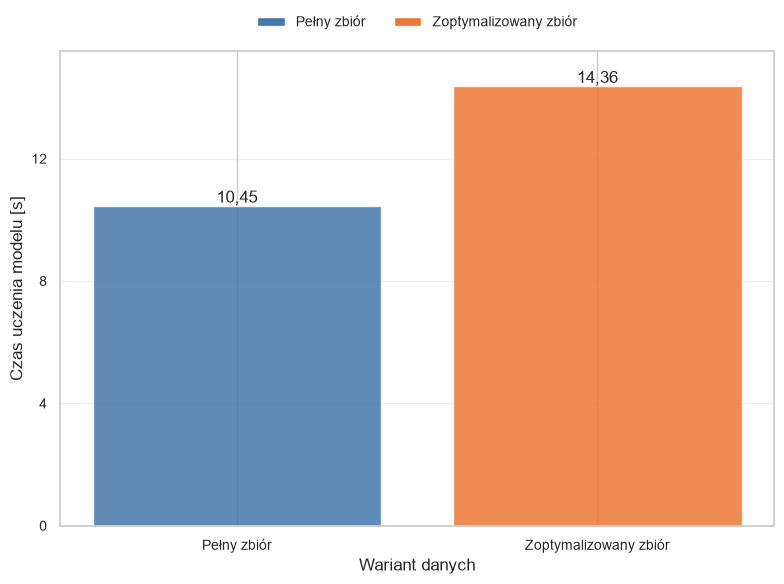

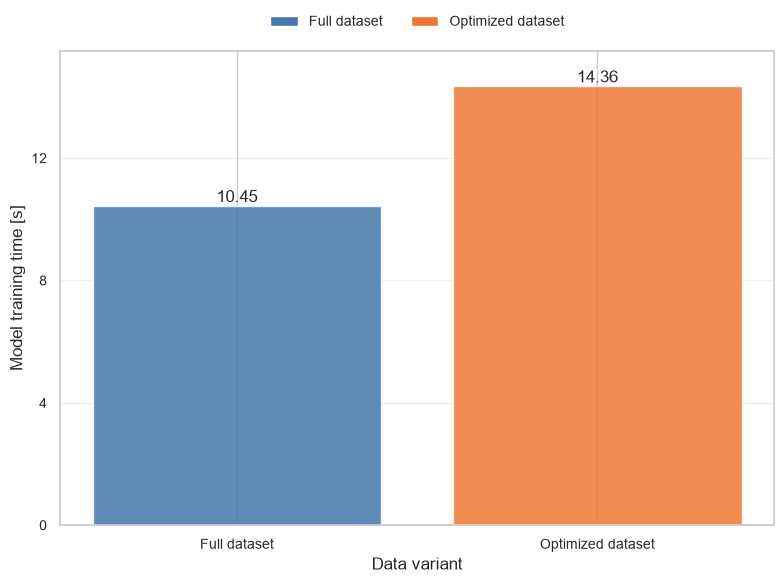

,Wariant danych,Liczba cech,Redukcja liczby cech,Redukcja [%]
0,Pełny zbiór,111,0,0.00
1,Zoptymalizowany zbiór,74,37,33.33


In [9]:
training_times = {}
feature_counts = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    training_times[dataset_name] = float(results_for_datasets[dataset_name]['training_time'])
    feature_counts[dataset_name] = int(len(data_splits[dataset_name]['X'].columns))
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'mlp_training_time.png'
    )
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'mlp_feature_count.png'
    )

time_figure, _ = plot_training_time_comparison(training_times)
save_comparison_figure(
    time_figure, PLOTS_DIR / 'mlp_training_time_comparison.png'
)
plt.show()

feature_count_rows = feature_count_comparison_rows(
    feature_counts['Pełny zbiór'],
    feature_counts['Zoptymalizowany zbiór'],
)
display(pd.DataFrame(feature_count_rows))


## 7.2a. Wizualizacja architektury sieci neuronowej



PEŁNY ZBIÓR


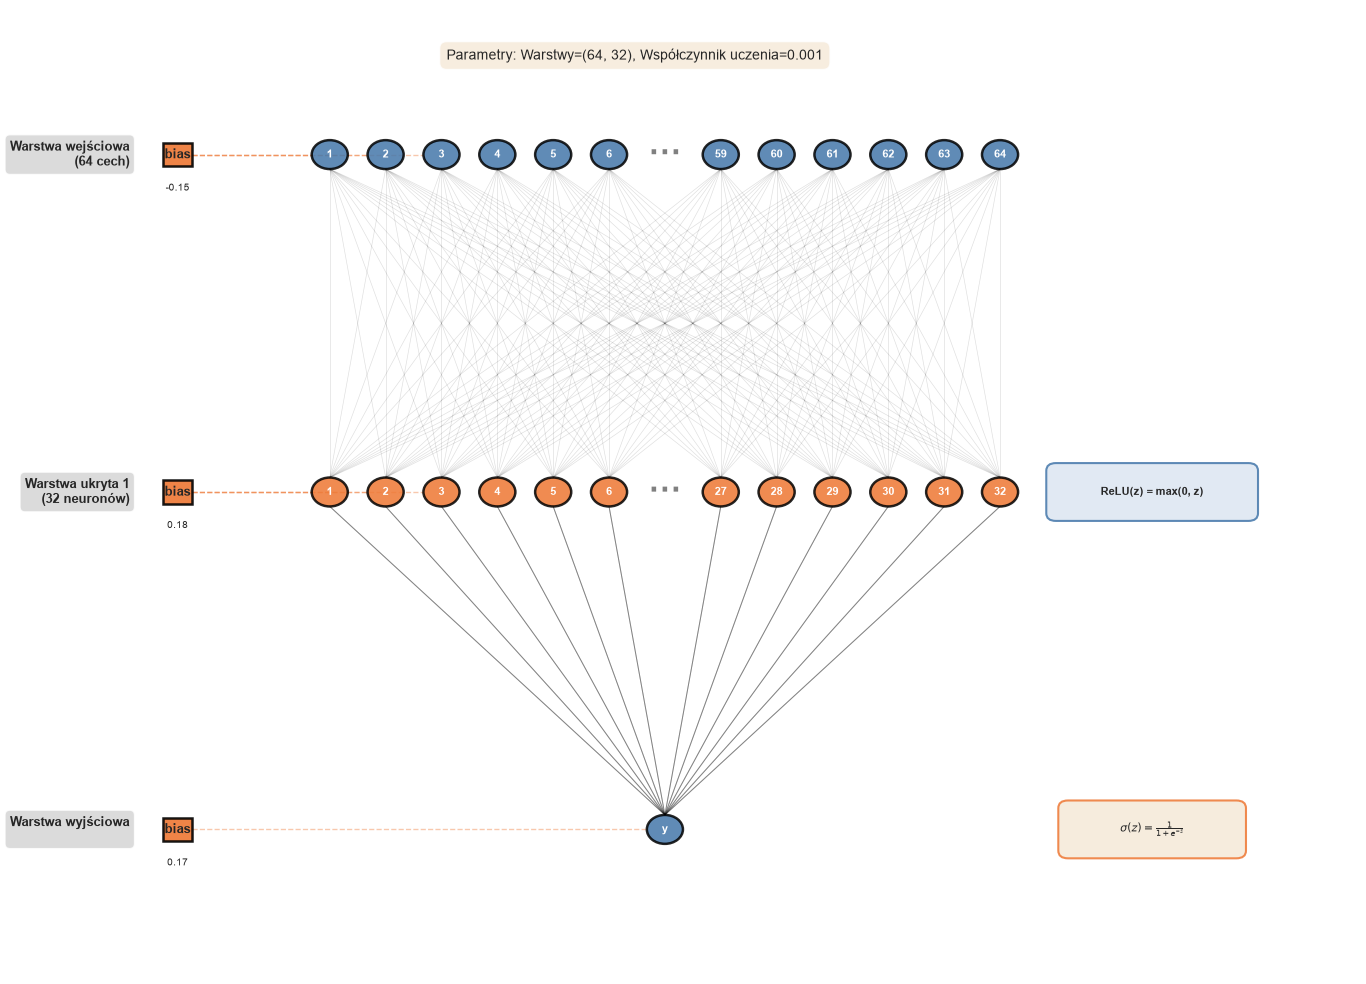

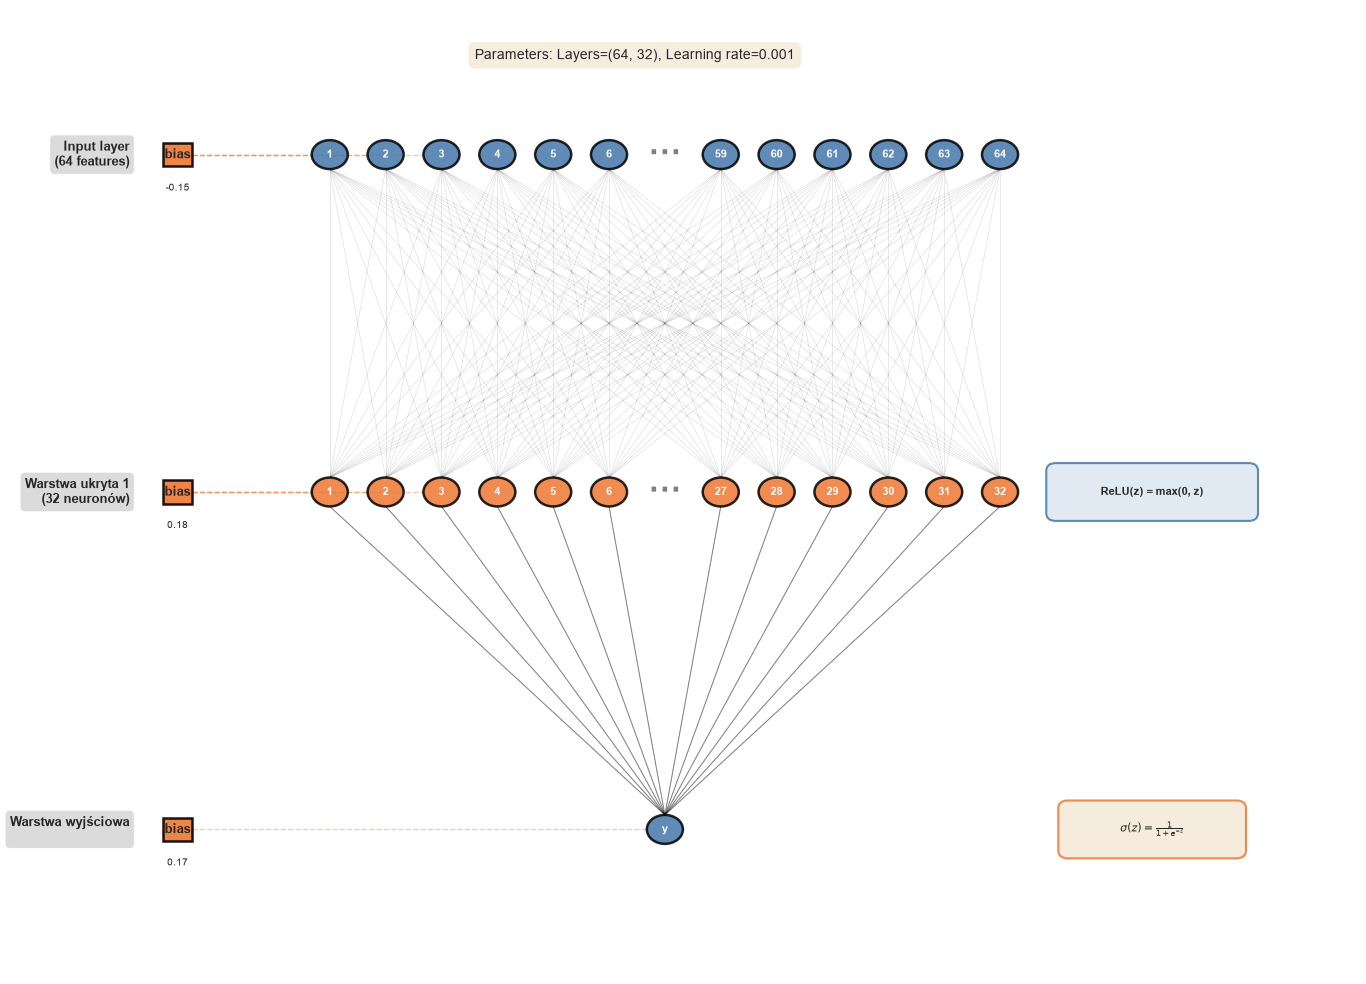

✅ Wizualizacja architektury zapisana: mlp_architecture_full.png

ZOPTYMALIZOWANY ZBIÓR


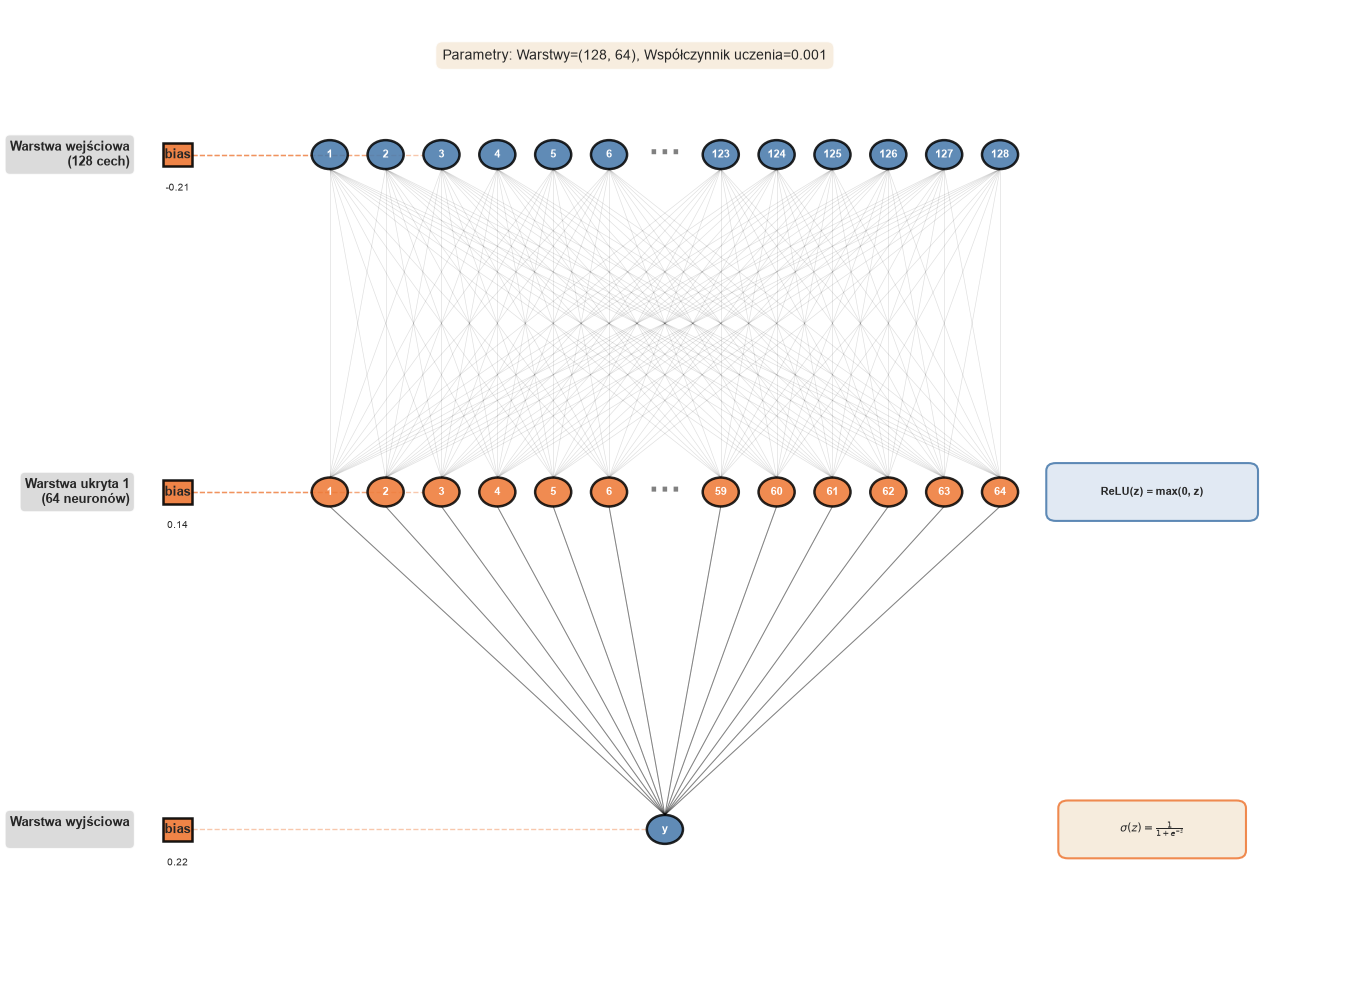

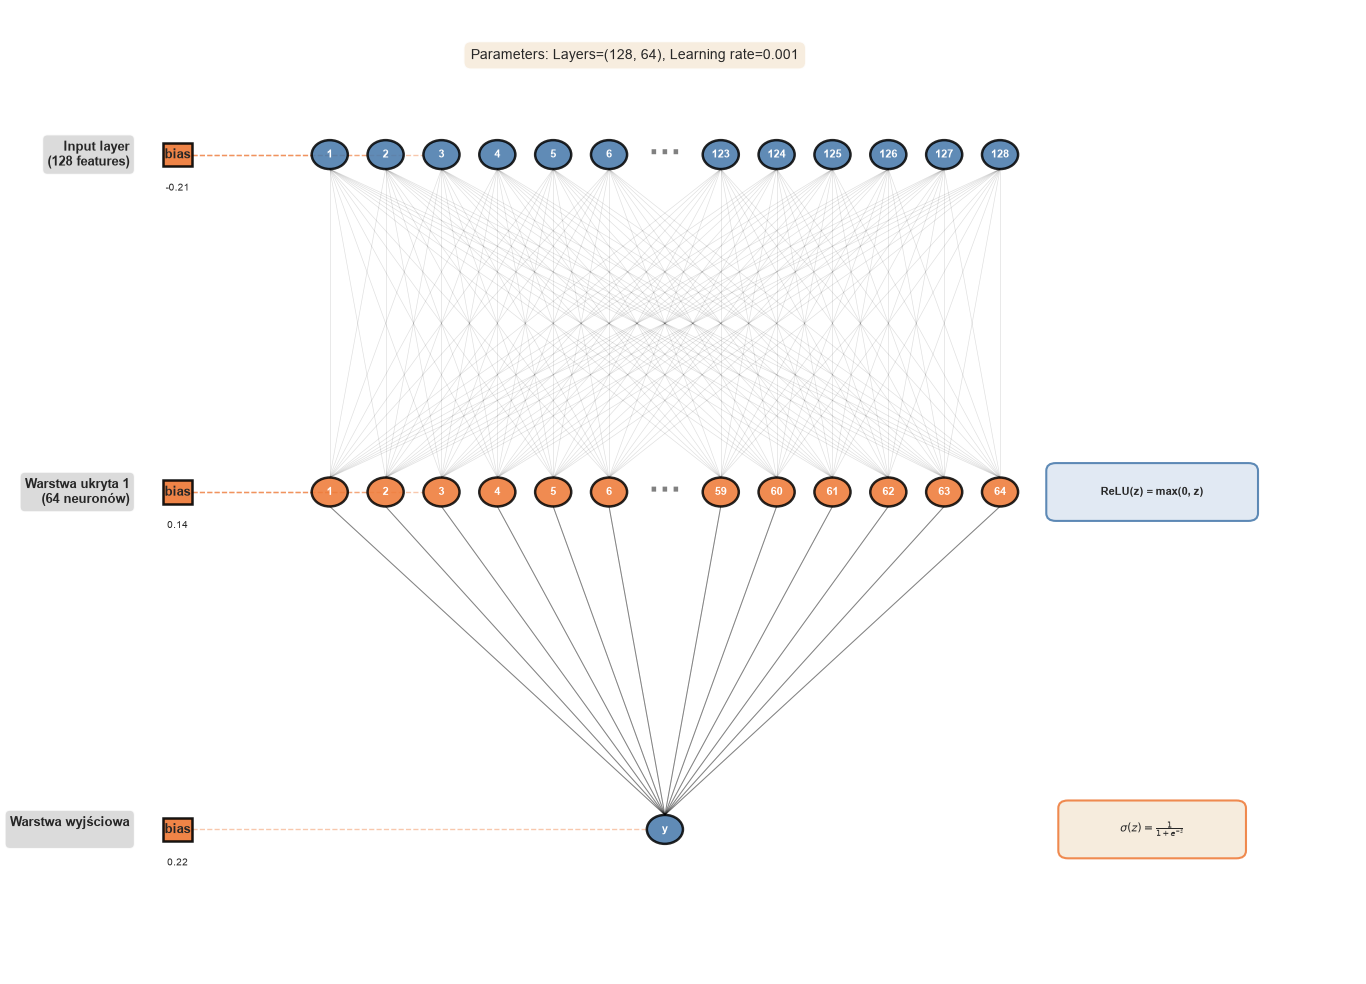

✅ Wizualizacja architektury zapisana: mlp_architecture_optimized.png

ARCHITEKTURA MODELU - PEŁNY ZBIÓR

Parametry:
  • Warstwy ukryte: (64, 32)
  • Współczynnik uczenia: 0.001

Warstwy sieci:
  1. Dense: 64 neuronów, funkcja aktywacji=relu, parametry=7,168
  2. Dropout: rate=0.2
  3. Dense: 32 neuronów, funkcja aktywacji=relu, parametry=2,080
  4. Dropout: rate=0.2
  5. Dense: 1 neuronów, funkcja aktywacji=sigmoid, parametry=33

Łączna liczba parametrów do wyuczenia: 9,281

ARCHITEKTURA MODELU - ZOPTYMALIZOWANY ZBIÓR

Parametry:
  • Warstwy ukryte: (128, 64)
  • Współczynnik uczenia: 0.001

Warstwy sieci:
  1. Dense: 128 neuronów, funkcja aktywacji=relu, parametry=9,600
  2. Dropout: rate=0.2
  3. Dense: 64 neuronów, funkcja aktywacji=relu, parametry=8,256
  4. Dropout: rate=0.2
  5. Dense: 1 neuronów, funkcja aktywacji=sigmoid, parametry=65

Łączna liczba parametrów do wyuczenia: 17,921


In [10]:
dataset_names_internal = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display_names = [dataset_display_name(name, data_splits[name]['feature_count']) for name in data_splits]

for idx, (dataset_name, display_name) in enumerate(zip(dataset_names_internal, dataset_display_names)):
    print(f"\n{'='*80}")
    print(f"{dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    best_params = results_for_datasets[dataset_name]['best_params']

    fig, ax = plt.subplots(1, 1, figsize=(14, 10))
    ax.axis('off')
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 10)

    dense_layers = []
    dropout_indices = []

    for i, layer in enumerate(model.layers):
        if hasattr(layer, 'units'):
            neurons = layer.get_config()['units']
            activation = layer.get_config().get('activation', 'N/A')
            weights = layer.get_weights()
            dense_layers.append({
                'neurons': neurons,
                'activation': activation,
                'weights': weights[0] if len(weights) > 0 else None,
                'bias': weights[1] if len(weights) > 1 else None
            })
        else:
            dropout_indices.append(len(dense_layers) - 1)

    ax.text(5, 9.6, f'Parametry: Warstwy={best_params["hidden_layers"]}, '
                    f'Współczynnik uczenia={best_params["learning_rate"]}',
            ha='center', va='top', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#F5E9D8', alpha=0.8))

    num_layers = len(dense_layers)
    y_positions = np.linspace(8.5, 1.5, num_layers)

    neuron_radius = 0.15
    neurons_to_show = 6

    all_layer_positions = []

    for layer_idx, layer_info in enumerate(dense_layers):
        y_center = y_positions[layer_idx]
        neurons = layer_info['neurons']
        activation = layer_info['activation']

        if neurons <= 12:
            neurons_display = list(range(neurons))
            show_ellipsis = False
        else:
            neurons_display = list(range(neurons_to_show)) + list(range(neurons - neurons_to_show, neurons))
            show_ellipsis = True

        total_width = 6.5
        if show_ellipsis:
            x_spacing = total_width / (len(neurons_display) + 2)
            x_positions_neurons = [2 + (i + 1) * x_spacing for i in range(neurons_to_show)]
            ellipsis_x = 2 + (neurons_to_show + 1) * x_spacing
            x_positions_neurons += [2 + (neurons_to_show + 2 + i) * x_spacing for i in range(neurons_to_show)]
        else:
            x_spacing = total_width / (neurons + 1)
            x_positions_neurons = [2 + (i + 1) * x_spacing for i in range(neurons)]

        if layer_idx == 0:
            layer_color = '#4477AA'
            layer_name = f'Warstwa wejściowa\n({neurons} cech)'
        elif layer_idx == num_layers - 1:
            layer_color = '#4477AA'
            layer_name = 'Warstwa wyjściowa\n'
        else:
            layer_color = '#EE7733'
            layer_name = f'Warstwa ukryta {layer_idx}\n({neurons} neuronów)'

        ax.text(0.8, y_center, layer_name,
               ha='right', va='center', fontsize=9, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.4', facecolor='lightgray', alpha=0.8))

        layer_neuron_positions = []
        for neuron_idx, x in enumerate(x_positions_neurons):
            circle = Circle((x, y_center), neuron_radius,
                          facecolor=layer_color, edgecolor='black',
                          linewidth=1.8, alpha=0.85, zorder=3)
            ax.add_patch(circle)

            if layer_idx == num_layers - 1:
                neuron_label = 'y'
            elif show_ellipsis:
                if neuron_idx < neurons_to_show:
                    neuron_label = str(neuron_idx + 1)
                else:
                    neuron_label = str(neurons - neurons_to_show + (neuron_idx - neurons_to_show) + 1)
            else:
                neuron_label = str(neuron_idx + 1)

            ax.text(x, y_center, neuron_label,
                   ha='center', va='center', fontsize=8, fontweight='bold', color='white')

            layer_neuron_positions.append((x, y_center))

        if show_ellipsis:
            ax.text(ellipsis_x, y_center, '···',
                   ha='center', va='center', fontsize=24, fontweight='bold', color='gray')

        all_layer_positions.append(layer_neuron_positions)

        if layer_info['bias'] is not None:
            bias_x = 1.2
            bias_y = y_center

            bias_square = Rectangle((bias_x - 0.12, bias_y - 0.12), 0.24, 0.24,
                                   facecolor='#EE7733', edgecolor='black',
                                   linewidth=1.8, alpha=0.9, zorder=3)
            ax.add_patch(bias_square)
            ax.text(bias_x, bias_y, 'bias', ha='center', va='center',
                   fontsize=9, fontweight='bold')

            for neuron_x, neuron_y in layer_neuron_positions[:3]:
                ax.plot([bias_x + 0.12, neuron_x - neuron_radius],
                       [bias_y, neuron_y],
                       color='#EE7733', alpha=0.4, linewidth=1.0, zorder=1, linestyle='--')

            avg_bias = np.mean(layer_info["bias"])
            ax.text(bias_x, bias_y - 0.3, f'{avg_bias:.2f}',
                   fontsize=7, ha='center', va='top')

        if layer_idx > 0:
            func_x = 9.3
            func_y = y_center

            if layer_idx == num_layers - 1:
                func_text = r'$\sigma(z) = \frac{1}{1+e^{-z}}$'
                func_color = '#F5E9D8'
                func_edge = '#EE7733'
                func_width = 1.4
            else:
                func_text = 'ReLU(z) = max(0, z)'
                func_color = '#DCE6F2'
                func_edge = '#4477AA'
                func_width = 1.6

            func_box = FancyBboxPatch((func_x - func_width/2, func_y - 0.22), func_width, 0.44,
                                     boxstyle="round,pad=0.08",
                                     facecolor=func_color, edgecolor=func_edge,
                                     linewidth=1.5, alpha=0.85, zorder=2)
            ax.add_patch(func_box)
            ax.text(func_x, func_y, func_text,
                   ha='center', va='center', fontsize=8, fontweight='bold')

    for layer_idx in range(len(all_layer_positions) - 1):
        current_positions = all_layer_positions[layer_idx]
        next_positions = all_layer_positions[layer_idx + 1]

        if layer_idx == 0 and len(current_positions) <= 12 and len(next_positions) <= 12:
            for x1, y1 in current_positions:
                for x2, y2 in next_positions:
                    ax.plot([x1, x2], [y1 - neuron_radius, y2 + neuron_radius],
                           color='black', alpha=0.12, linewidth=0.5, zorder=0)
        elif len(current_positions) <= 10 and len(next_positions) <= 10:
            for x1, y1 in current_positions:
                for x2, y2 in next_positions:
                    ax.plot([x1, x2], [y1 - neuron_radius, y2 + neuron_radius],
                           color='black', alpha=0.15, linewidth=0.6, zorder=0)
        else:
            representative_next = [0, len(next_positions)//2, len(next_positions)-1]

            for curr_idx in range(len(current_positions)):
                for next_idx in representative_next:
                    if next_idx < len(next_positions):
                        x1, y1 = current_positions[curr_idx]
                        x2, y2 = next_positions[next_idx]
                        ax.plot([x1, x2], [y1 - neuron_radius, y2 + neuron_radius],
                               color='black', alpha=0.2, linewidth=0.7, zorder=0)

    plt.tight_layout()

    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'
    subdir = DATASET_SUBDIR[dataset_name]
    save_dataset_figure(fig, PLOTS_DIR, dataset_name, 'mlp_architecture.png')
    plt.show()

    print(f"✅ Wizualizacja architektury zapisana: mlp_architecture_{file_suffix}.png")

for dataset_name in dataset_names_internal:
    print(f"\n{'='*80}")
    print(f"ARCHITEKTURA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    best_params = results_for_datasets[dataset_name]['best_params']

    print(f"\nParametry:")
    print(f"  • Warstwy ukryte: {best_params['hidden_layers']}")
    print(f"  • Współczynnik uczenia: {best_params['learning_rate']}")

    print(f"\nWarstwy sieci:")
    total_params = 0
    for i, layer in enumerate(model.layers):
        layer_config = layer.get_config()
        layer_type = layer.__class__.__name__

        if hasattr(layer, 'units'):
            neurons = layer_config['units']
            activation = layer_config.get('activation', 'N/A')
            params = layer.count_params()
            total_params += params
            print(f"  {i+1}. {layer_type}: {neurons} neuronów, funkcja aktywacji={activation}, parametry={params:,}")
        else:
            rate = layer_config.get('rate', 'N/A')
            print(f"  {i+1}. {layer_type}: rate={rate}")

    print(f"\nŁączna liczba parametrów do wyuczenia: {total_params:,}")


## 7.2b. Przykładowe wyniki klasyfikacji MLP

Każdy wykres przedstawia rozkład prawdopodobieństwa klas dla jednej próbki ze
zbioru testowego. Oś pozioma przedstawia przewidywane prawdopodobieństwo, a oś
pionowa — klasy rozpatrywane przez model.


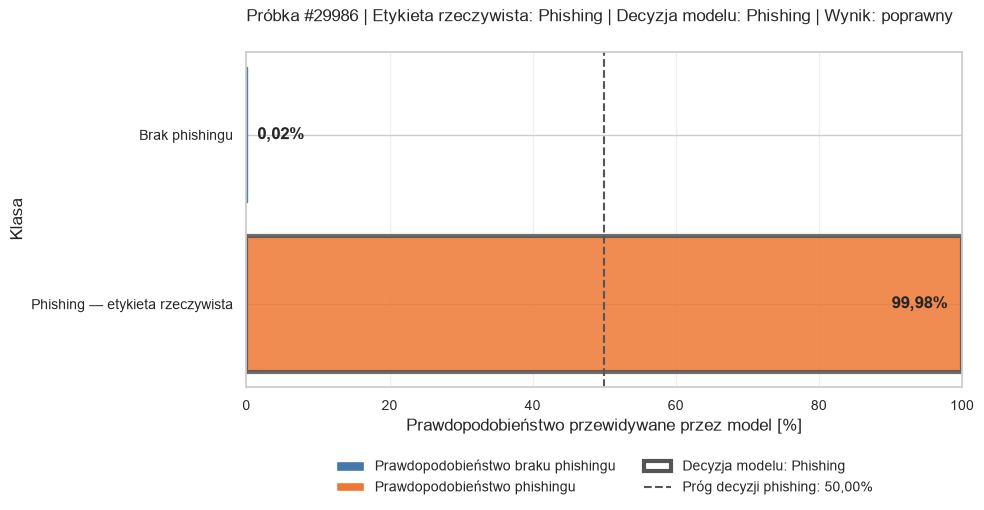

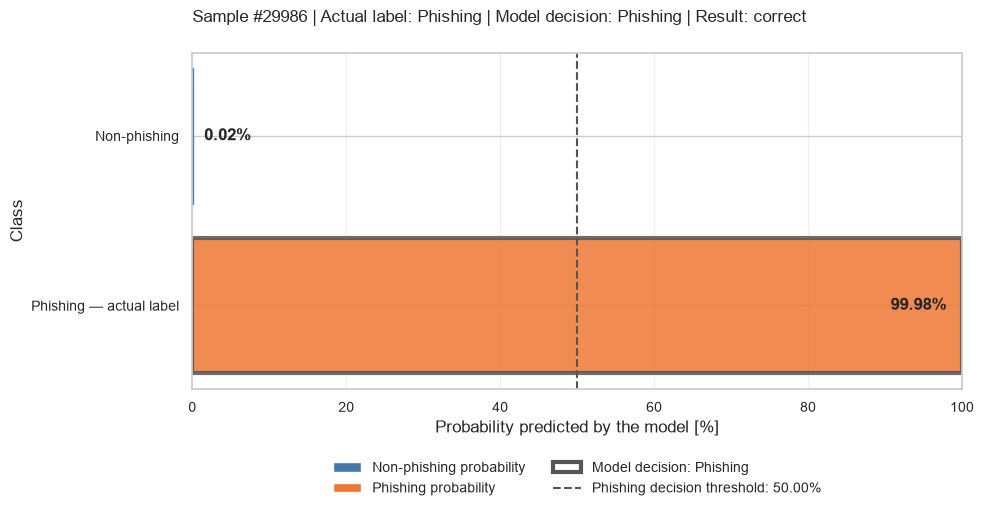

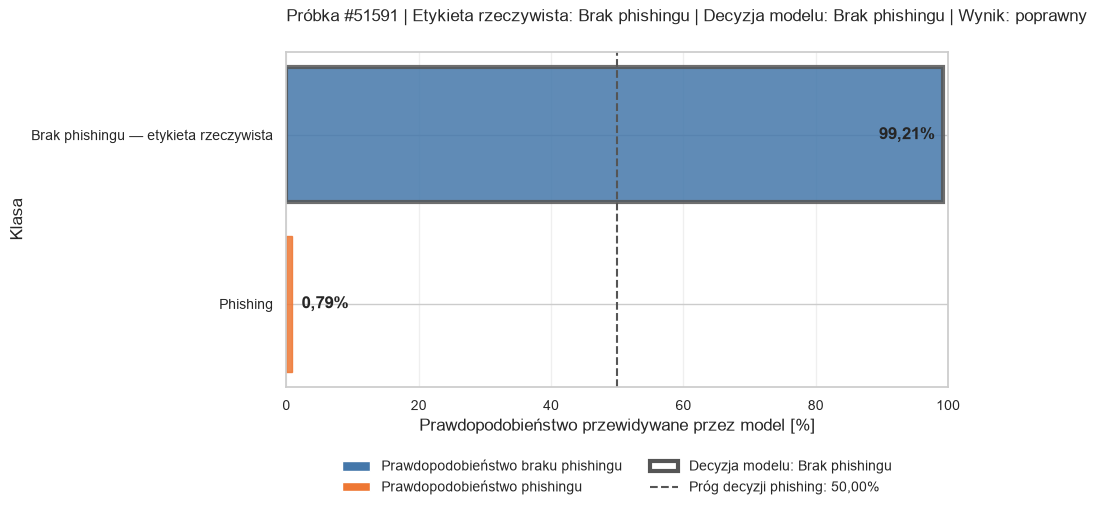

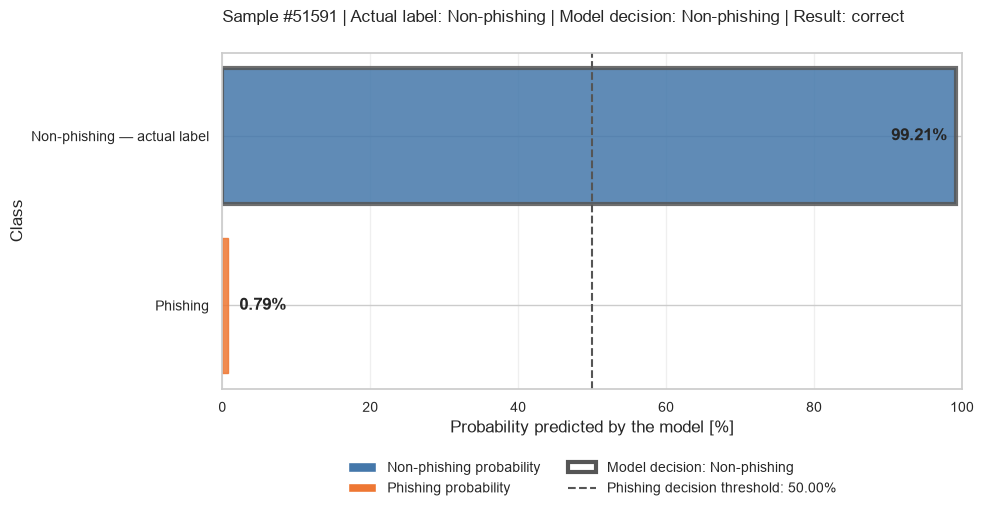

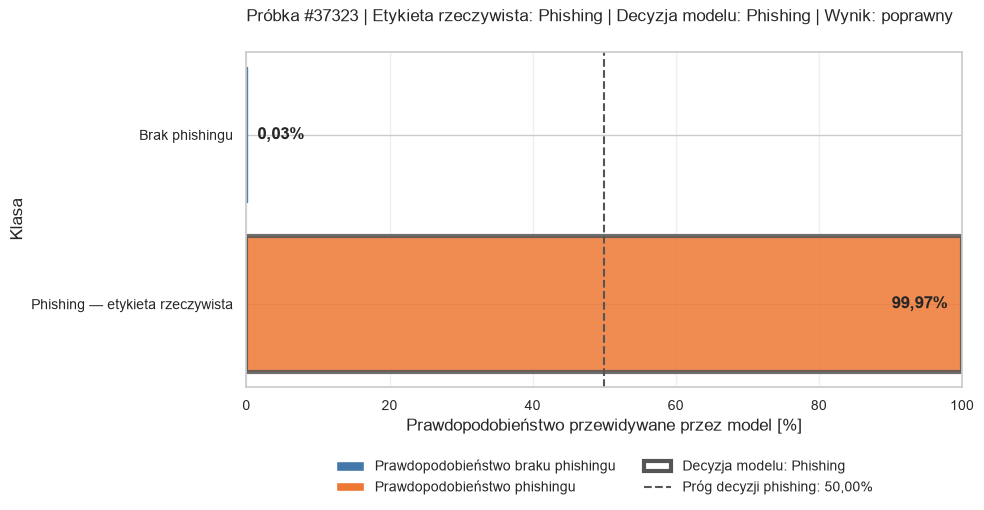

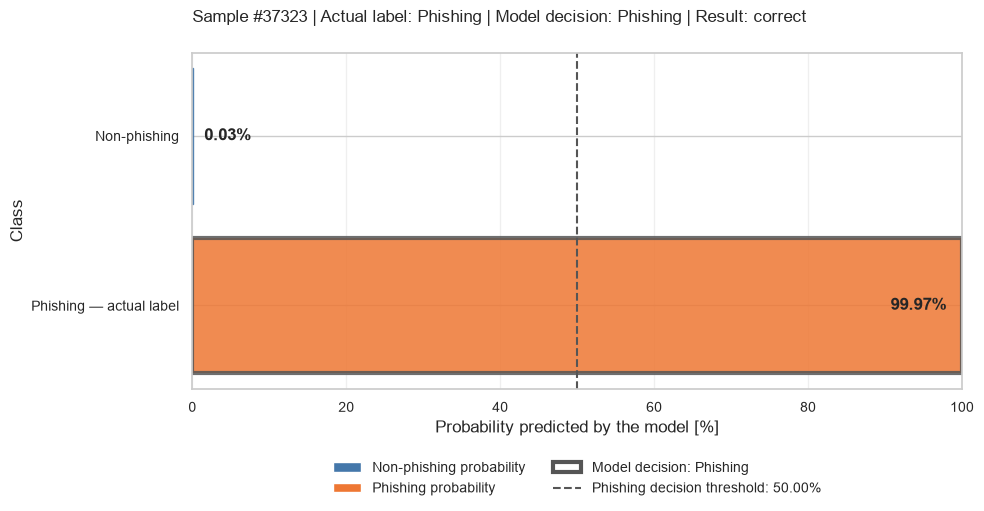

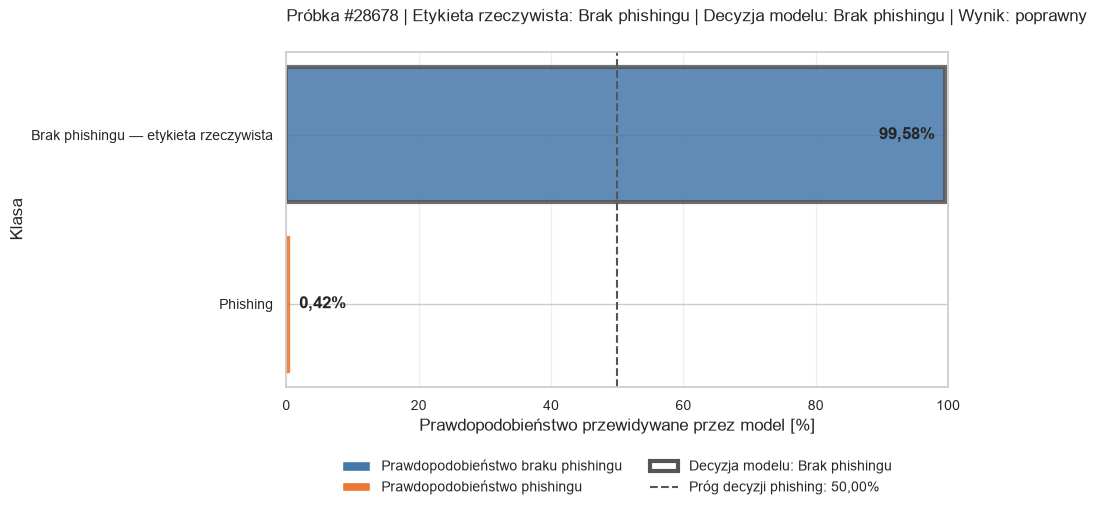

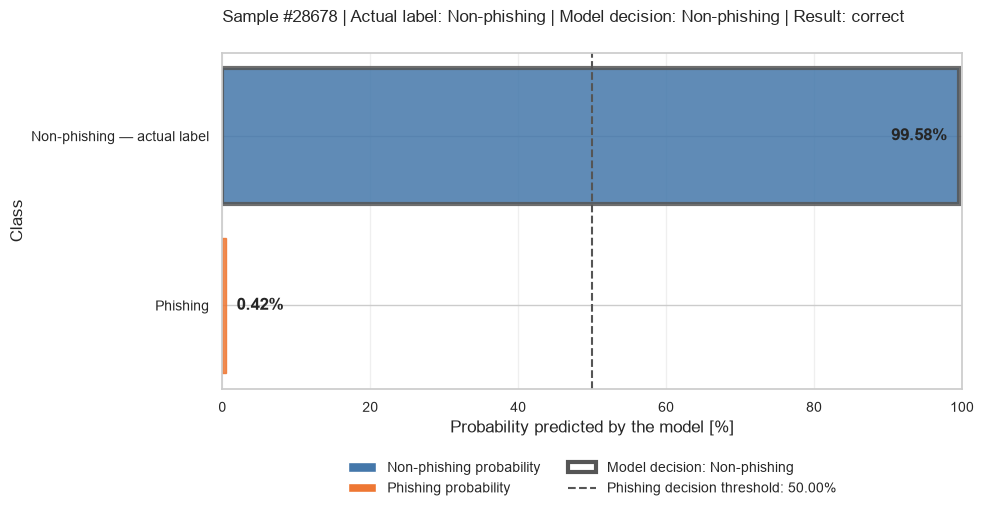

In [11]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    true_labels = data_splits[dataset_name]['y_test']
    label_values = np.asarray(true_labels, dtype=int)
    probabilities = np.asarray(
        evaluation_results[dataset_name]['y_pred_proba'], dtype=float
    ).reshape(-1)
    threshold = evaluation_results[dataset_name].get('decision_threshold', 0.5)
    sample_positions = {
        'phishing': int(np.flatnonzero(label_values == 1)[0]),
        'bez_phishingu': int(np.flatnonzero(label_values == 0)[0]),
    }
    for sample_kind, position in sample_positions.items():
        sample_id = (
            true_labels.index[position]
            if hasattr(true_labels, 'index') else position
        )
        for language in ['pl', 'en']:
            language_folder = 'pl' if language == 'pl' else 'eng'
            figure, _ = plot_sample_probability_prediction(
                probabilities[position], label_values[position], sample_id,
                decision_threshold=threshold, language=language,
            )
            save_dataset_figure(
                figure, PLOTS_DIR, dataset_name,
                f'{language_folder}/mlp_sample_prediction_{sample_kind}.png',
            )
            plt.show()
    for obsolete_name in [
        'mlp_prediction_example_phishing.png',
        'mlp_prediction_example_bez_phishingu.png',
        'mlp_prediction_examples.png',
        'mlp_probability_distribution.png',
        'mlp_sample_prediction_phishing.png',
        'mlp_sample_prediction_bez_phishingu.png',
        'mlp_sample_prediction_phishing_pl.png',
        'mlp_sample_prediction_phishing_en.png',
        'mlp_sample_prediction_bez_phishingu_pl.png',
        'mlp_sample_prediction_bez_phishingu_en.png',
    ]:
        remove_dataset_figure(PLOTS_DIR, dataset_name, obsolete_name)


## 7.3. Macierz pomyłek i krzywe ROC


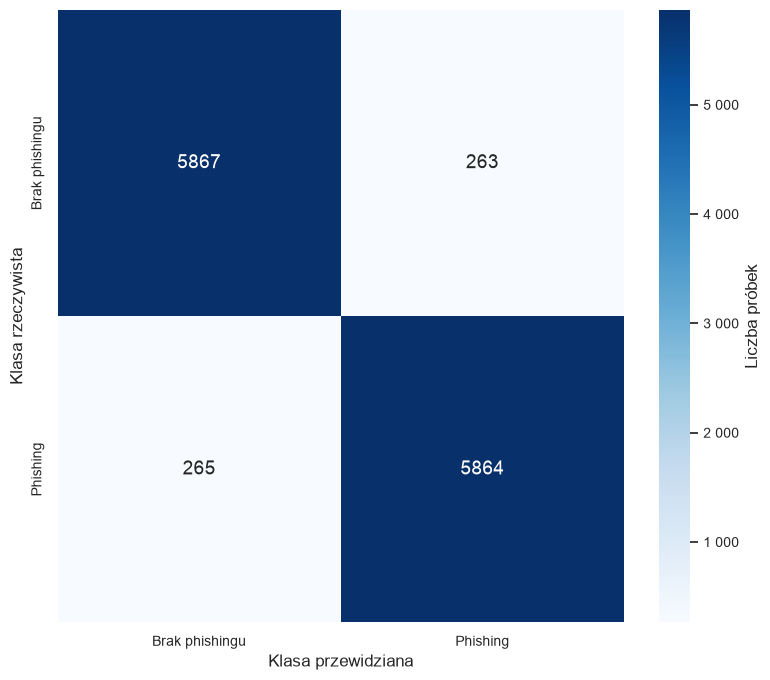

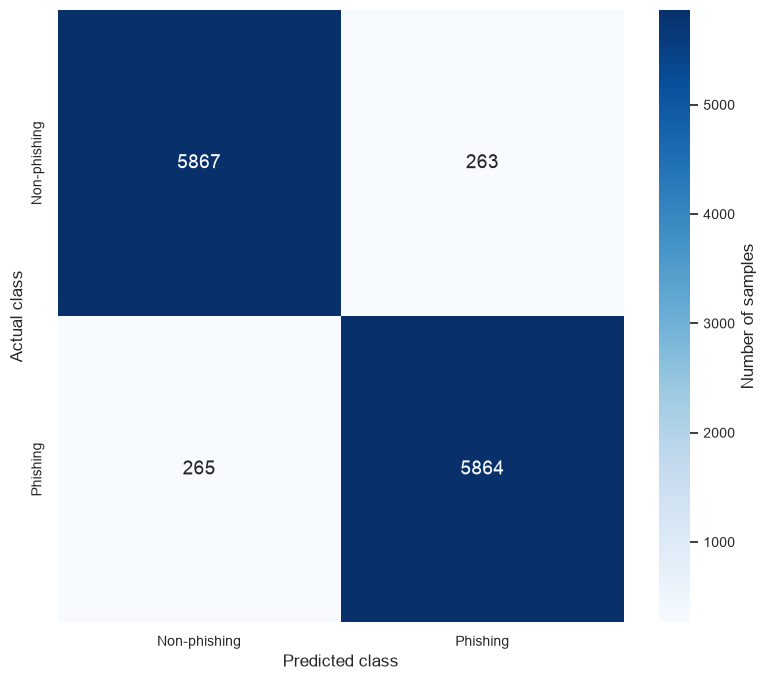

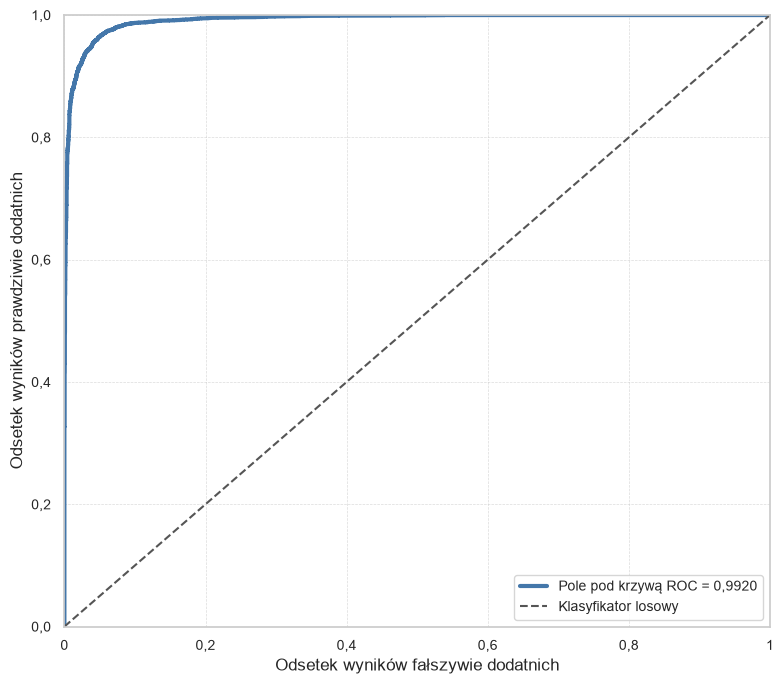

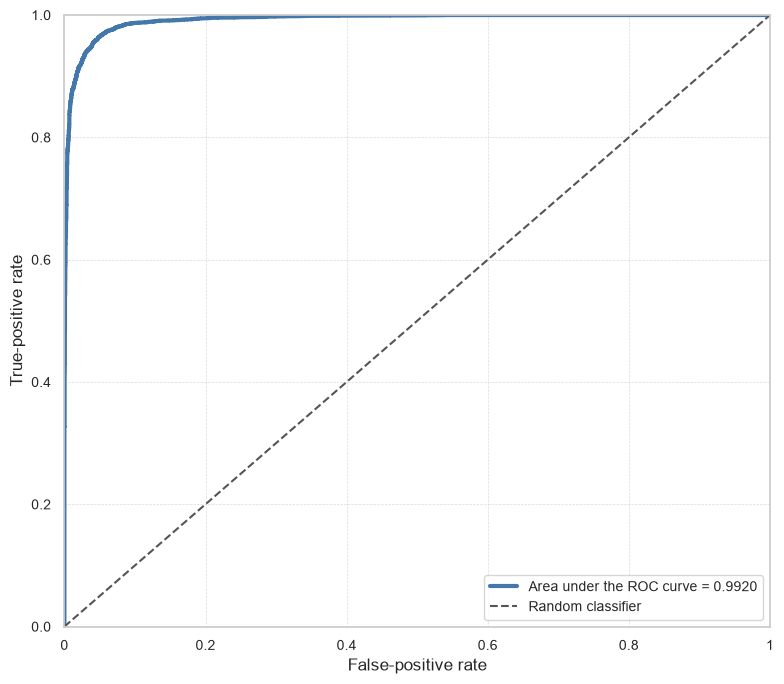

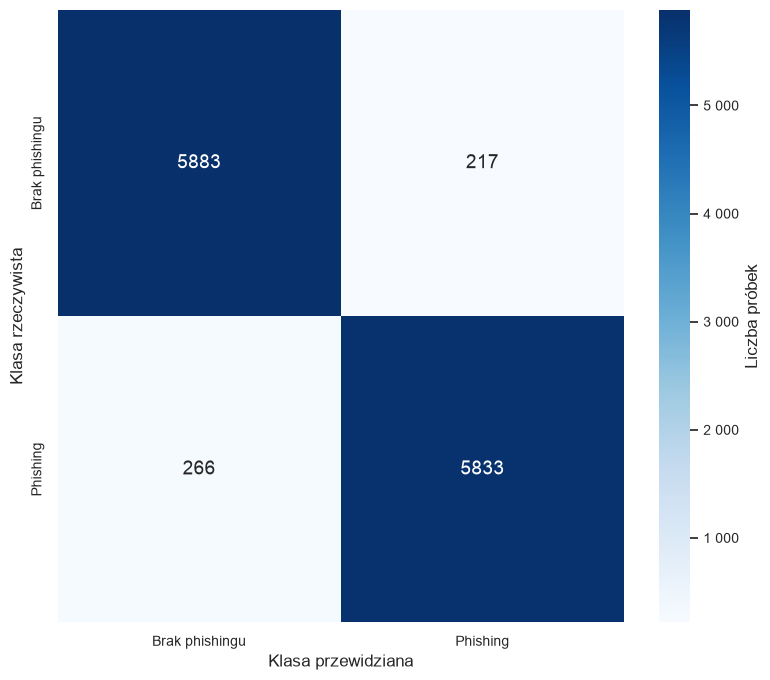

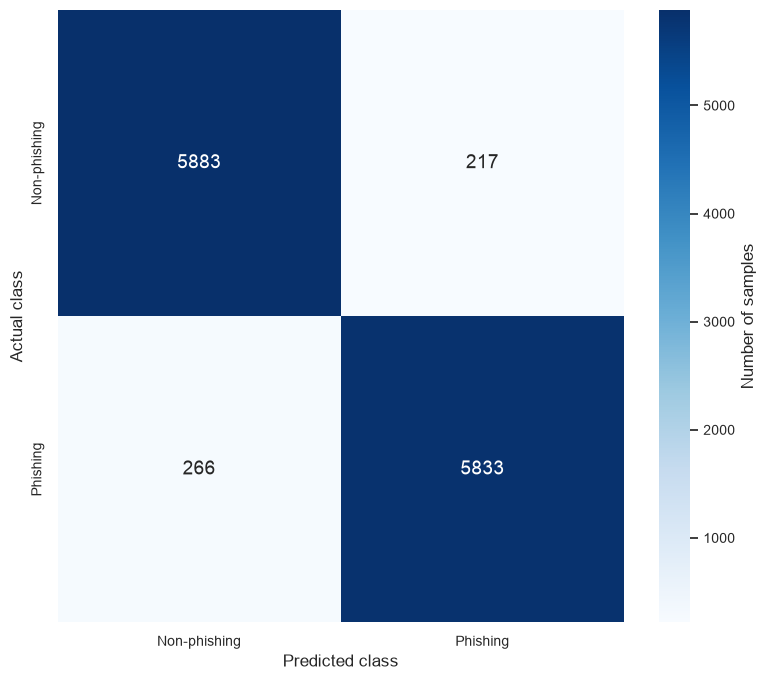

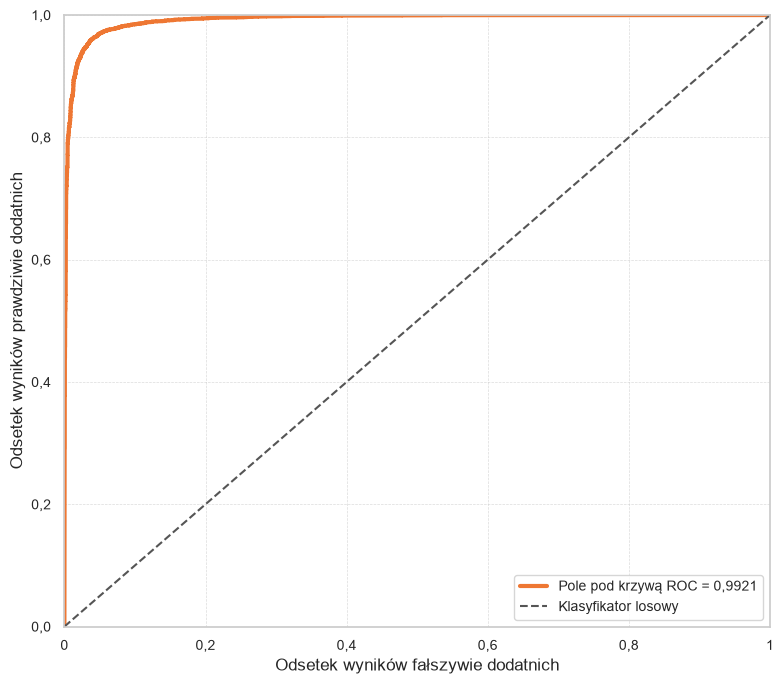

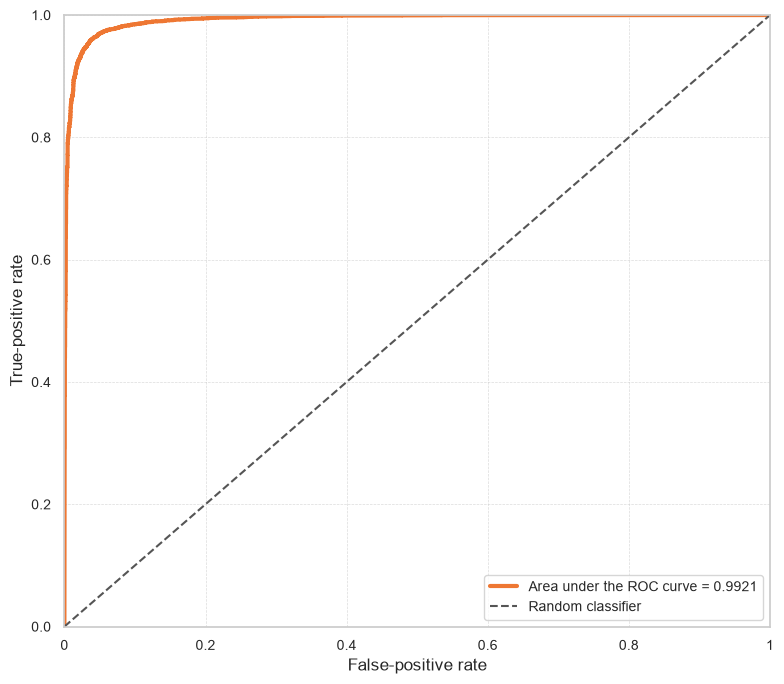

In [12]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    evaluation = evaluation_results[dataset_name]

    confusion_figure, _ = plot_confusion_matrix(
        evaluation['confusion_matrix'], dataset_name,
    )
    save_dataset_figure(
        confusion_figure, PLOTS_DIR, dataset_name, 'mlp_confusion_matrix.png'
    )
    plt.show()

    roc_figure, _ = plot_roc_curve(
        results_for_datasets[dataset_name]['y_test'], evaluation['y_pred_proba'], evaluation['auc_roc'], dataset_name,
    )
    save_dataset_figure(
        roc_figure, PLOTS_DIR, dataset_name, 'mlp_roc_curve.png'
    )
    plt.show()


## 7.3a. Krzywe AUC-ROC w zależności od epoki


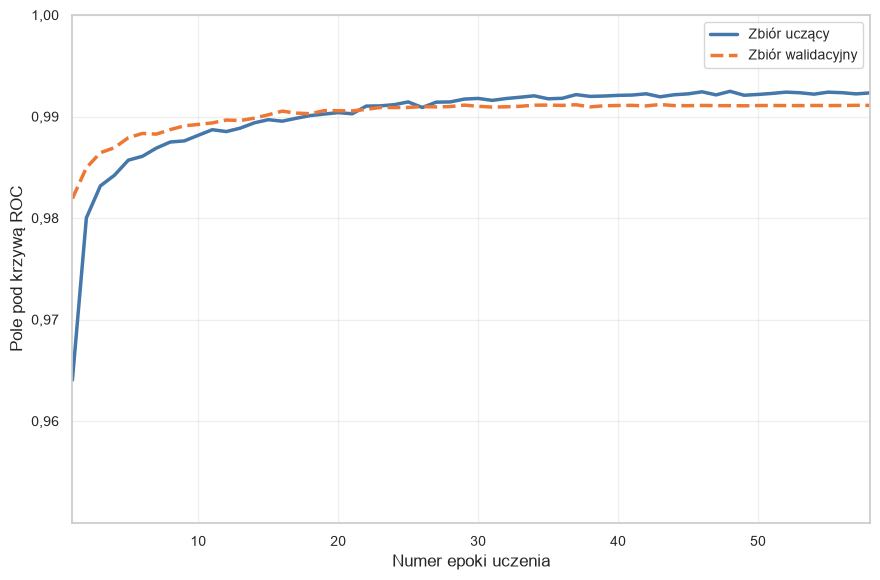

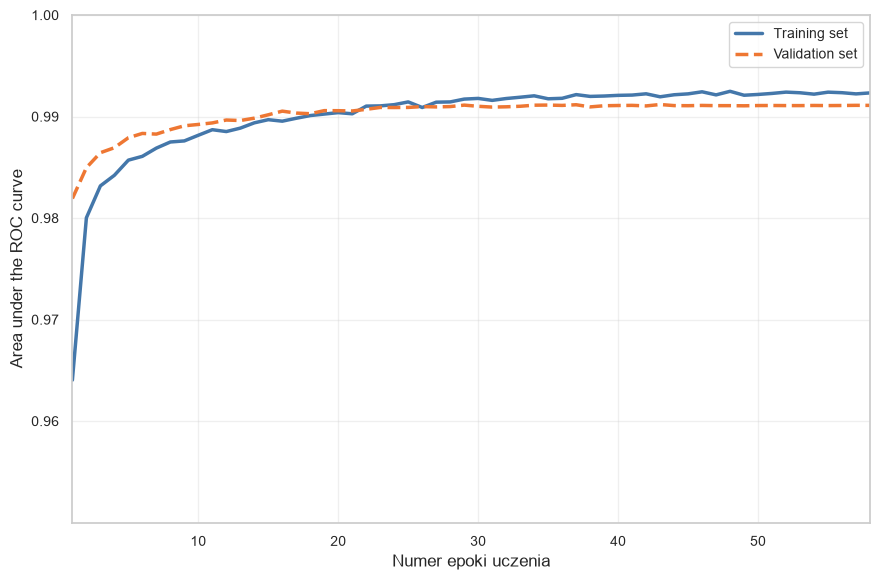

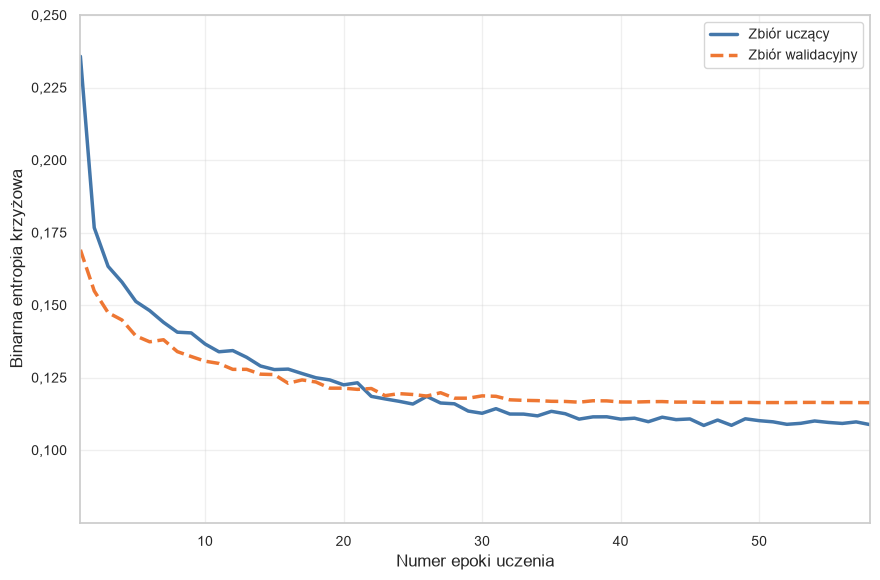

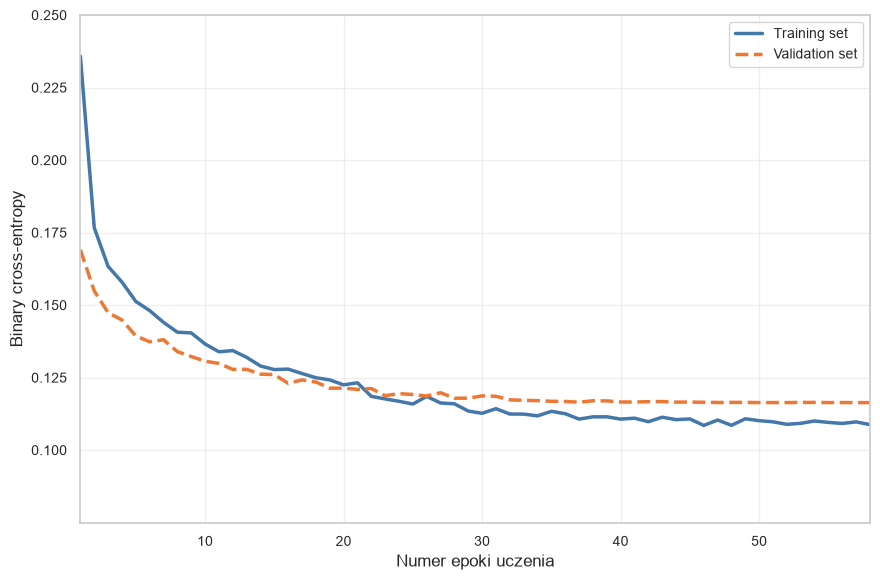

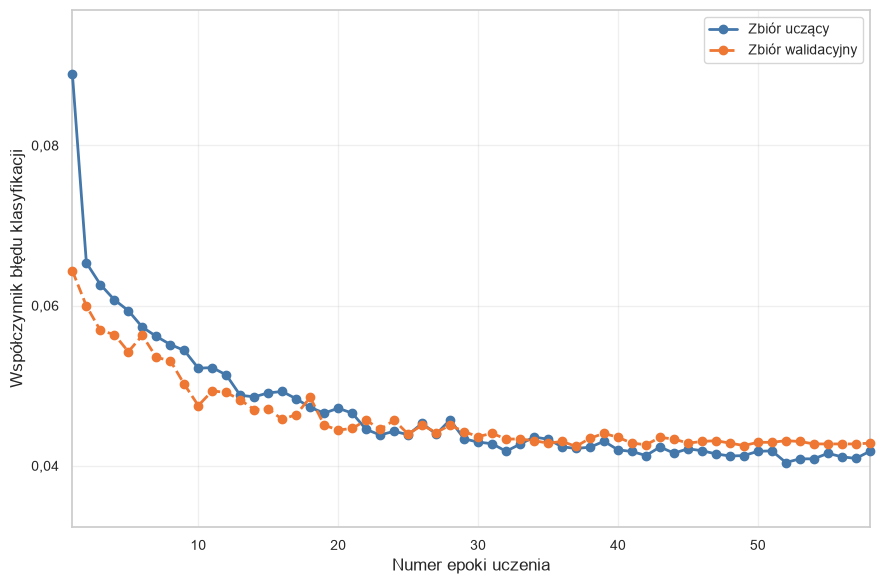

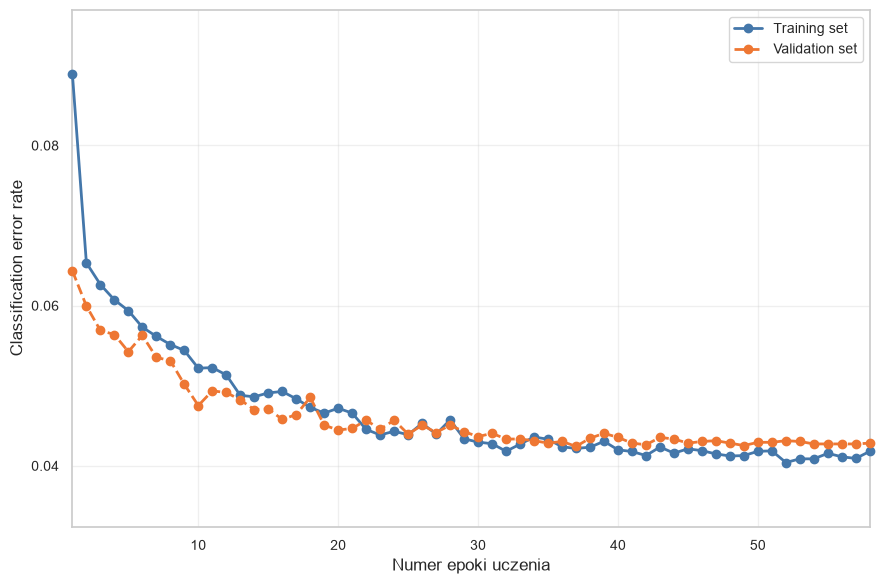

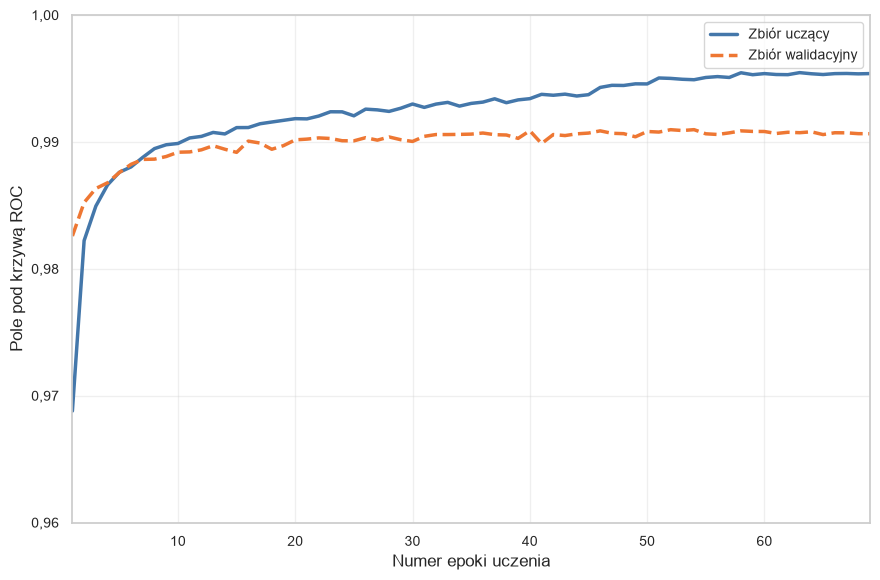

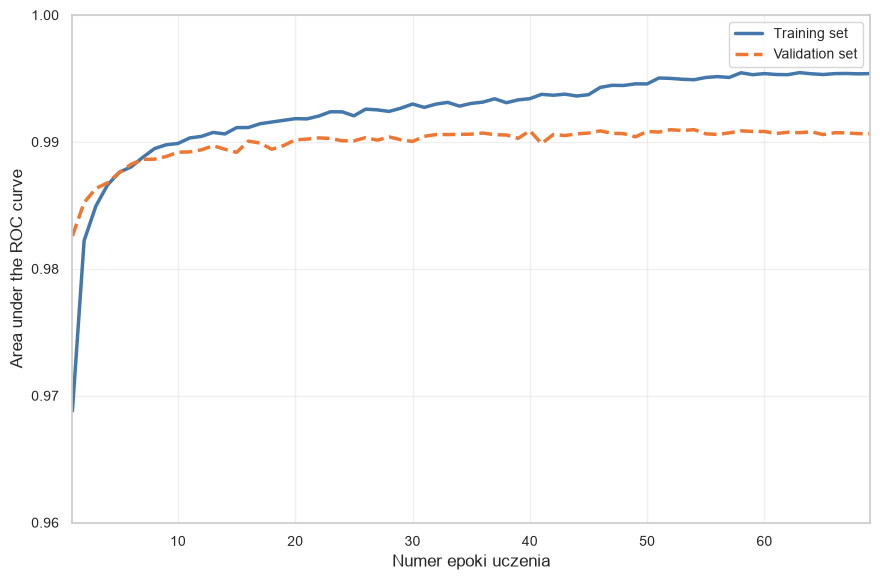

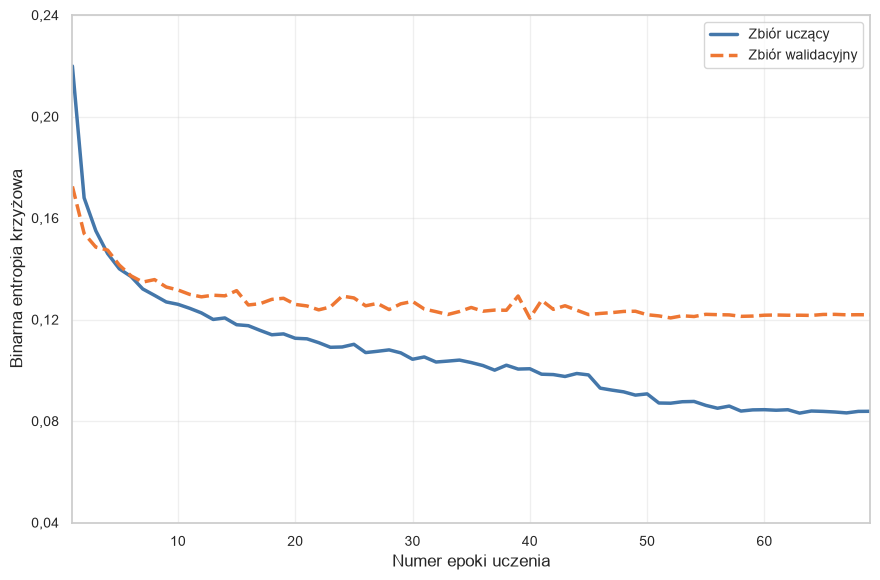

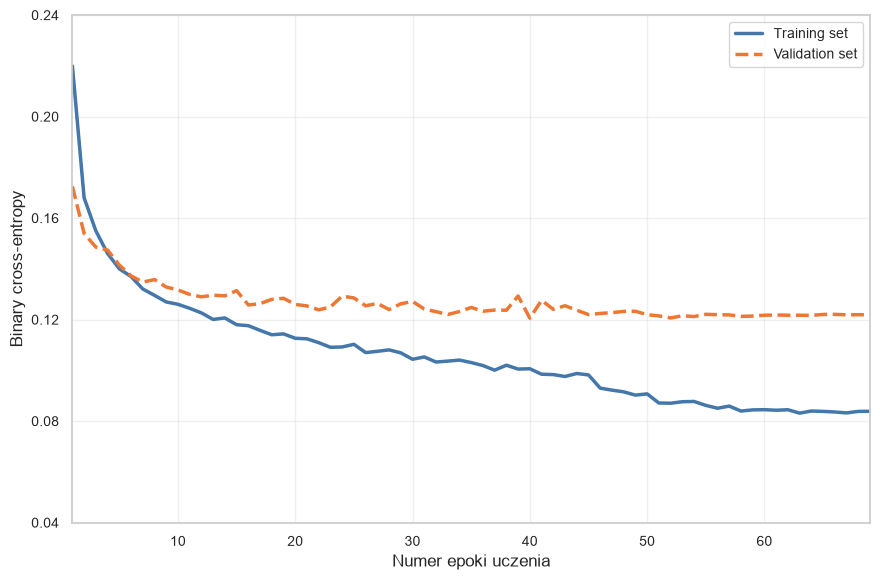

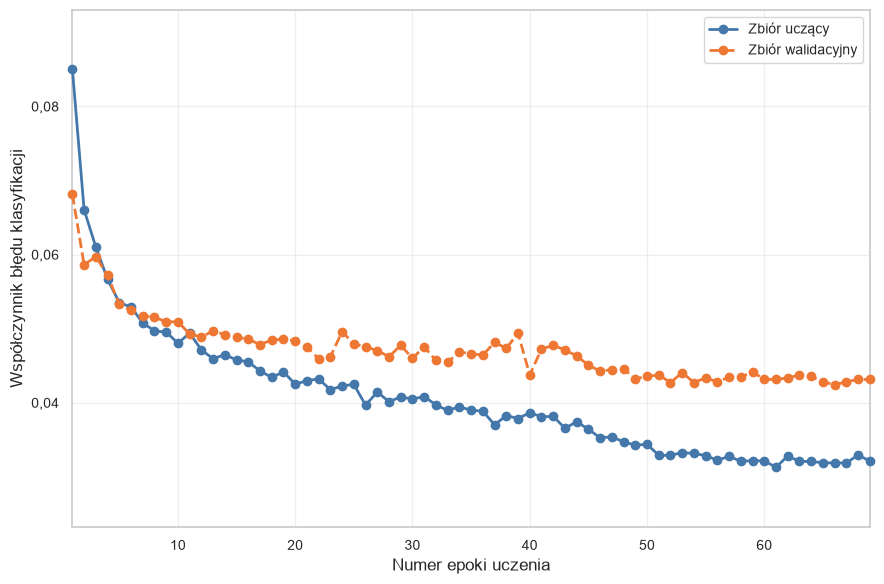

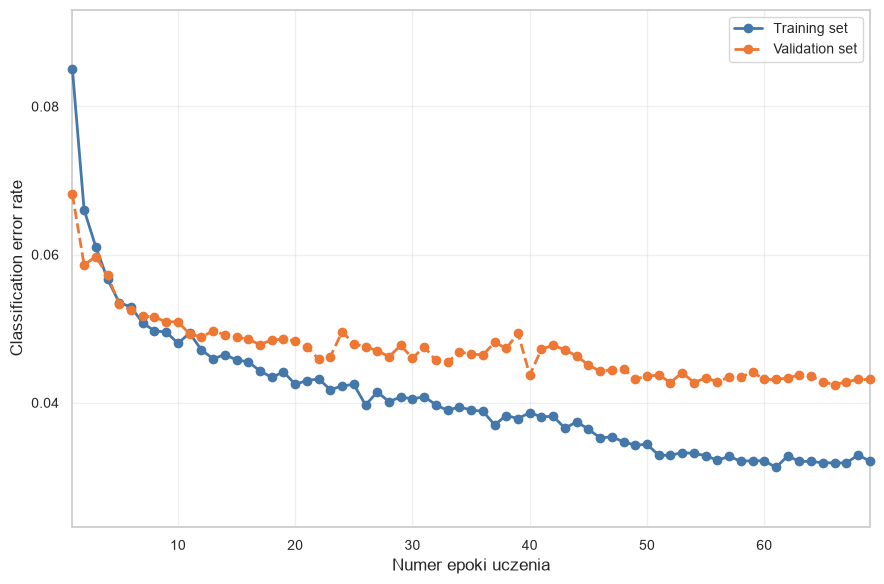

In [13]:
dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']

for dataset_name in dataset_names:
    result = results_for_datasets[dataset_name]
    history = result['history'].history
    epochs = np.arange(1, len(history['val_loss']) + 1)
    auc_limits = shared_limits([
        result['epoch_end_train_auc'], history['val_auc'],
    ], padding_ratio=0.08, floor=0.0, ceiling=1.0)
    loss_limits = shared_limits([
        result['epoch_end_train_loss'], history['val_loss'],
    ], padding_ratio=0.08, floor=0.0)

    figure, axis = plt.subplots(figsize=(9, 6))
    axis.plot(epochs, result['epoch_end_train_auc'], label='Zbiór uczący',
              color=TRAIN_COLOR, linewidth=2.5)
    axis.plot(epochs, history['val_auc'], label='Zbiór walidacyjny',
              color=VALIDATION_COLOR, linewidth=2.5, linestyle='--')
    configure_numeric_x_axis(axis, 'Numer epoki uczenia')
    axis.set_ylabel('Pole pod krzywą ROC')
    axis.set_ylim(*auc_limits)
    configure_axis_limit_ticks(axis, 'y')
    axis.legend()
    axis.grid(True, alpha=0.3)
    figure.tight_layout(pad=1.2)
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'mlp_auc_epochs.png')
    plt.show()

    figure, axis = plt.subplots(figsize=(9, 6))
    axis.plot(epochs, result['epoch_end_train_loss'],
              label='Zbiór uczący',
              color=TRAIN_COLOR, linewidth=2.5)
    axis.plot(epochs, history['val_loss'],
              label='Zbiór walidacyjny',
              color=VALIDATION_COLOR, linewidth=2.5, linestyle='--')
    configure_numeric_x_axis(axis, 'Numer epoki uczenia')
    axis.set_ylabel('Binarna entropia krzyżowa')
    axis.set_ylim(*loss_limits)
    configure_axis_limit_ticks(axis, 'y')
    axis.legend()
    axis.grid(True, alpha=0.3)
    figure.tight_layout(pad=1.2)
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'mlp_error_curves.png')
    plt.show()

    figure, _ = plot_parameter_train_validation_error(
        epochs,
        1.0 - np.asarray(result['epoch_end_train_accuracy']),
        1.0 - np.asarray(result['epoch_end_validation_accuracy']),
        x_label='Numer epoki uczenia', logarithmic_x=False,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'mlp_epoch_train_validation_error.png')
    plt.show()


## 7.5. Ważność cech w obu modelach


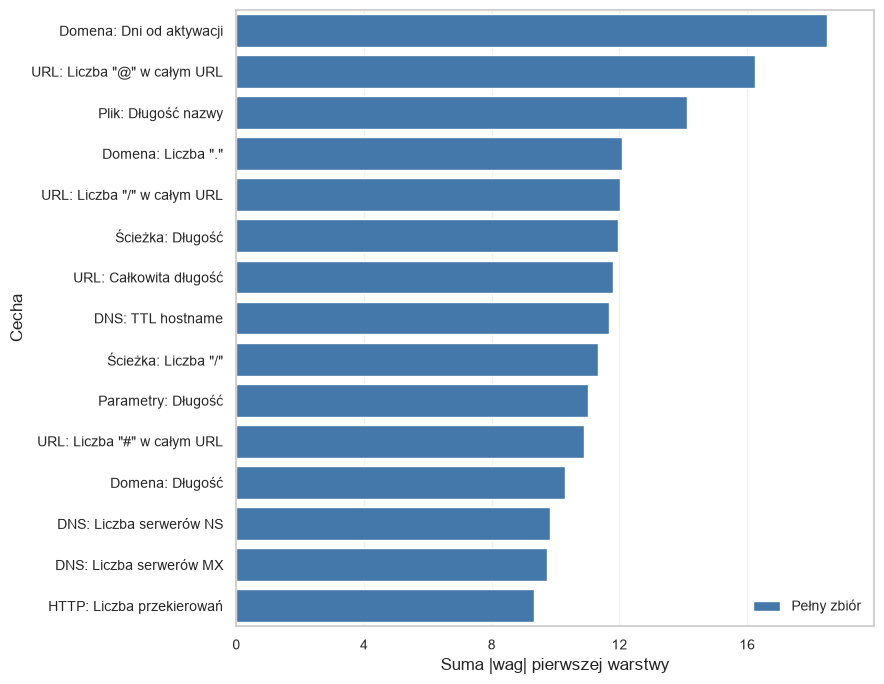

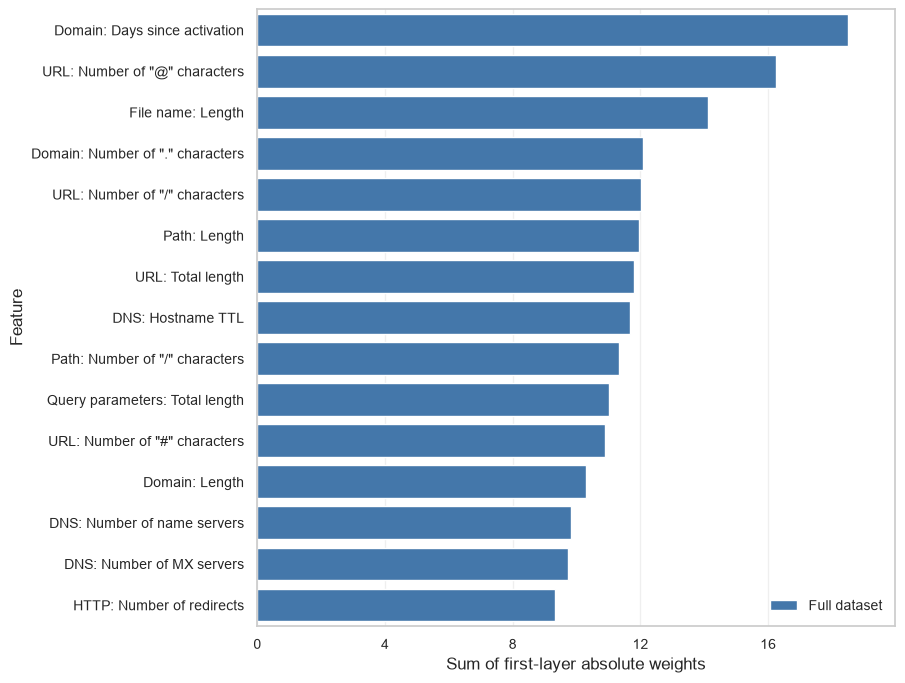

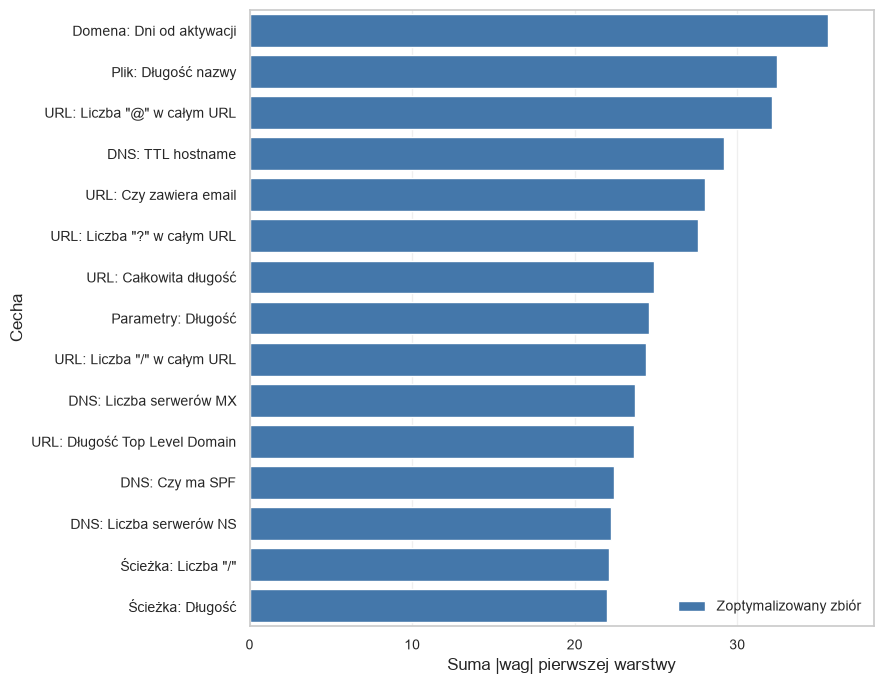

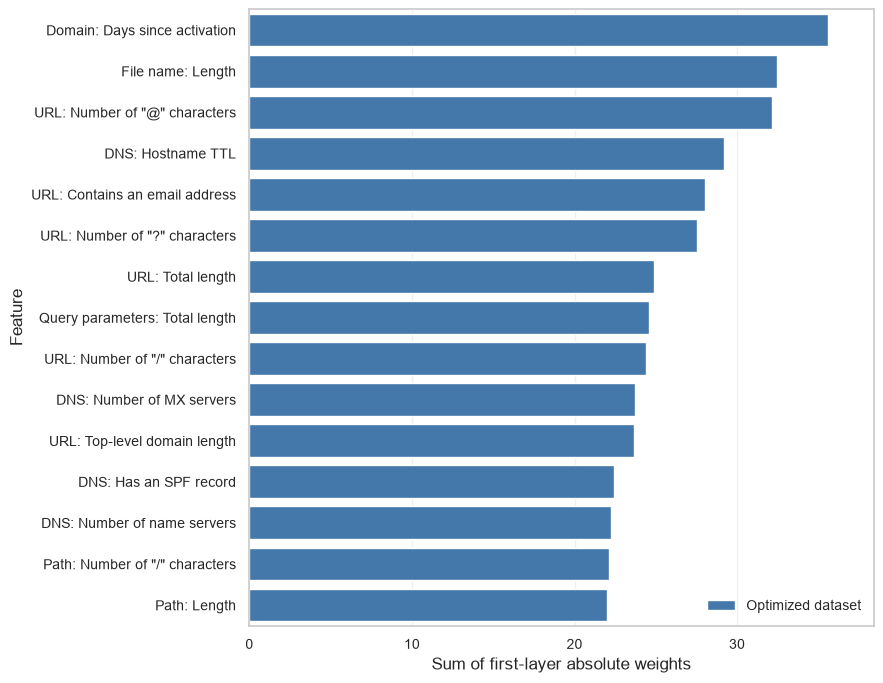

In [14]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = results_for_datasets[dataset_name]['model']
    X_features = data_splits[dataset_name]['X']
    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(column) for column in X_features.columns],
        'Ważność': np.abs(model.layers[0].get_weights()[0]).sum(axis=1),
    }).sort_values('Ważność', ascending=False).head(15)
    figure, _ = plot_feature_ranking(
        feature_importance, dataset_name, x_column='Ważność', x_label='Suma |wag| pierwszej warstwy'
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'mlp_feature_importance.png')
    plt.show()


## 8. Zapis modeli i wyników


In [15]:
comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results['Pełny zbiór']['accuracy'], evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [evaluation_results['Pełny zbiór']['precision'], evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [evaluation_results['Pełny zbiór']['recall'], evaluation_results['Zoptymalizowany zbiór']['recall']],
    'Miara F1': [evaluation_results['Pełny zbiór']['f1'], evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [evaluation_results['Pełny zbiór']['auc_roc'], evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Czas uczenia (s)': [results_for_datasets['Pełny zbiór']['training_time'], results_for_datasets['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [len(data_splits['Pełny zbiór']['X'].columns), len(data_splits['Zoptymalizowany zbiór']['X'].columns)],
    'Średnie CPU [%]': [results_for_datasets[name]['resource_stats']['cpu']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalne CPU [%]': [results_for_datasets[name]['resource_stats']['cpu']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średni RAM [GB]': [results_for_datasets[name]['resource_stats']['ram']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalny RAM [GB]': [results_for_datasets[name]['resource_stats']['ram']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Próbki pomiarowe': [results_for_datasets[name]['resource_stats']['samples'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']]
})

comparison_path = backend_root.parent / 'results' / 'original' / 'model_comparisons' / 'mlp_comparison.csv'
comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)
print(f"✓ Porównanie zapisane: {comparison_path}")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'

    model_data = {
        'model': results_for_datasets[dataset_name]['model'],
        'scaler': data_splits[dataset_name]['scaler'],
        'feature_names': data_splits[dataset_name]['X'].columns.tolist(),
        'best_params': results_for_datasets[dataset_name]['best_params'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc']
        }
    }

    model_path = f'{MODELS_DIR}/mlp_model_{file_suffix}.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model_data, f)
    print(f"✓ Model zapisany: {model_path}")

    scaler_path = f'{MODELS_DIR}/mlp_scaler_{file_suffix}.pkl'
    with open(scaler_path, 'wb') as f:
        pickle.dump(data_splits[dataset_name]['scaler'], f)
    print(f"✓ Skaler zapisany: {scaler_path}")

print(f"\n{'='*80}")
print("PODSUMOWANIE KOŃCOWE")
print(f"{'='*80}")
print(f"\nPrzeszkolono i zapisano modele MLP dla obu zbiorów:")
print(f"  1. Model na pełnym zbiorze: {len(data_splits['Pełny zbiór']['X'].columns)} cech")
print(f"  2. Model na zoptymalizowanym zbiorze: {len(data_splits['Zoptymalizowany zbiór']['X'].columns)} cech")
print(f"\nWizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")

✓ Porównanie zapisane: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/model_comparisons/mlp_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  Miara F1  AUC-ROC  Czas uczenia (s)  Liczba cech  Średnie CPU [%]  Maksymalne CPU [%]  Średni RAM [GB]  Maksymalny RAM [GB]  Próbki pomiarowe
          Pełny zbiór    0.956930  0.957075 0.956763  0.956919 0.992008         10.446019          111        13.039364           19.070723         0.591682             0.606689               181
Zoptymalizowany zbiór    0.960407  0.964132 0.956386  0.960244 0.992141         14.359067           74        13.566504           19.640737         0.588374             0.592926               250
✓ Model zapisany: ../models/mlp/mlp_model_full.pkl
✓ Skaler zapisany: ../models/mlp/mlp_scaler_full.pkl
✓ Model zapisany: ../models/mlp/mlp_model_optimized.pkl
✓ Skaler zapisany: ../models/mlp/mlp_scaler_optimized.pkl

PODSUMOWANIE KOŃCOWE

Prze